### **PREDICTING BEHAVIOUR TO RETAIN CUSTOMERS**
**(Responsible AI Focused Analysis)**

Submitted by: Prathiba Reddy Namireddy

**PRIMARY RESEARCH BEFORE JUMPING INTO THE MODEL BUILDING PROCESS**

*Do Bias Exist in the Telecom Industry?*

*   Socioeconomic Bias (Senior Citizens vs Non-Senior Citizens)
*   Gender Bias
*   Payment Method Bias
*   Contract Type Bias

Thus, added a dedicated **Bias Detection & Fairness Analysis** section that checks for potential bias

*Which Metric to use for this Business Context*


*   True Positive (TP): Correctly identifying churners. Opportunity to retain
*   True Negative (TN): Correctly identifying loyal customers. No action needed
*   False Positive (FP): Predicting a customer WILL churn, but they DON'T. Less costly
*   False Negative (FN): Predicting a customer WON'T churn, but they DO. VERY COSTLY (lost revenue, acquisition cost for replacement ~5-25x retention cost)

Thus, in this scenario **Recall (sensitivity)** is more important than precision in this context. We'd rather over-predict churn and offer retention incentives to some loyal customers than miss actual churners.



**IMPORTING THE NECESSARY LIBRARIES**

In [9]:
# Core Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Preprocessing & Modeling
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

# Imbalance Handling
!pip install imbalanced-learn -q
from imblearn.over_sampling import SMOTE, ADASYN, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
from imblearn.combine import SMOTETomek
from imblearn.pipeline import Pipeline as ImbPipeline

# Metrics
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             roc_curve, precision_recall_curve, average_precision_score)

# Explainability Tools
!pip install shap lime anchor-exp -q
import shap
import lime
import lime.lime_tabular
from anchor import anchor_tabular

# Fairness Tools
!pip install fairlearn aif360 -q
from fairlearn.metrics import MetricFrame, selection_rate, demographic_parity_difference, equalized_odds_difference
from fairlearn.reductions import ExponentiatedGradient, DemographicParity, EqualizedOdds

# Anomaly Detection
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor

# Visualization
from sklearn.tree import plot_tree
from sklearn.inspection import PartialDependenceDisplay, permutation_importance


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 3.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 427.3/427.3 kB 11.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 251.6/251.6 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 259.7/259.7 kB 17.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.3/37.3 MB 18.1 MB/s eta 0:00:00


**DATA LOADING & INITIAL EXPLORATION**

In [8]:
import pandas as pd
import io

# Read the raw file content
with open('WA_Fn-UseC_-Telco-Customer-Churn.csv.xls - WA_Fn-UseC_-Telco-Customer-Chur.csv', 'r') as f:
    # Remove quotes from each line
    lines = [line.strip().strip('"') for line in f.readlines()]

# Join lines back and read as CSV
content = '\n'.join(lines)
df = pd.read_csv(io.StringIO(content))

print(df.columns.tolist())
print(f"\nNumber of columns: {len(df.columns)}")
print(f"Shape: {df.shape}")
print(df.head())

['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Number of columns: 21
Shape: (7043, 21)
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1 

**DATA CLEANING & PREPROCESSING**

In [10]:
# Convert numeric columns
df['SeniorCitizen'] = df['SeniorCitizen'].astype(int)
df['tenure'] = df['tenure'].astype(int)
df['MonthlyCharges'] = pd.to_numeric(df['MonthlyCharges'], errors='coerce')
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')


In [11]:
missing_values = df.isnull().sum()
missing_pct = (df.isnull().sum() / len(df)) * 100

missing_df = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage': missing_pct
})
print(missing_df[missing_df['Missing Values'] > 0])


              Missing Values  Percentage
TotalCharges              11    0.156183


In [12]:
print("\n   Tenure values for missing TotalCharges:")
print(df[df['TotalCharges'].isnull()]['tenure'].value_counts())
#These are likely new customers with tenure = 0, the ones with the null values


   Tenure values for missing TotalCharges:
tenure
0    11
Name: count, dtype: int64


In [13]:
# Fill missing TotalCharges with MonthlyCharges (for tenure = 1 month)
df['TotalCharges'].fillna(df['MonthlyCharges'], inplace=True)

In [14]:
print("\n📌 Step 3: Checking Duplicates...")
duplicates = df.duplicated().sum()
print(f"   Duplicate rows: {duplicates}")


📌 Step 3: Checking Duplicates...
   Duplicate rows: 0


In [15]:
print("\n📌 Step 4: Data Types Summary")
print(df.dtypes)


📌 Step 4: Data Types Summary
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object


**EXPLORATORY DATA ANALYSIS (EDA)**

In [17]:
churn_counts = df['Churn'].value_counts()
churn_pct = df['Churn'].value_counts(normalize=True) * 100

print(f"\n   Churn Distribution:")
print(f"   • No (Retained):  {churn_counts['No']:,} ({churn_pct['No']:.2f}%)")
print(f"   • Yes (Churned):  {churn_counts['Yes']:,} ({churn_pct['Yes']:.2f}%)")
print(f"\n   Class Imbalance Detected: {churn_pct['No']:.1f}% vs {churn_pct['Yes']:.1f}%")



   Churn Distribution:
   • No (Retained):  5,174 (73.46%)
   • Yes (Churned):  1,869 (26.54%)

   Class Imbalance Detected: 73.5% vs 26.5%



📌 5.2 DEMOGRAPHIC ANALYSIS


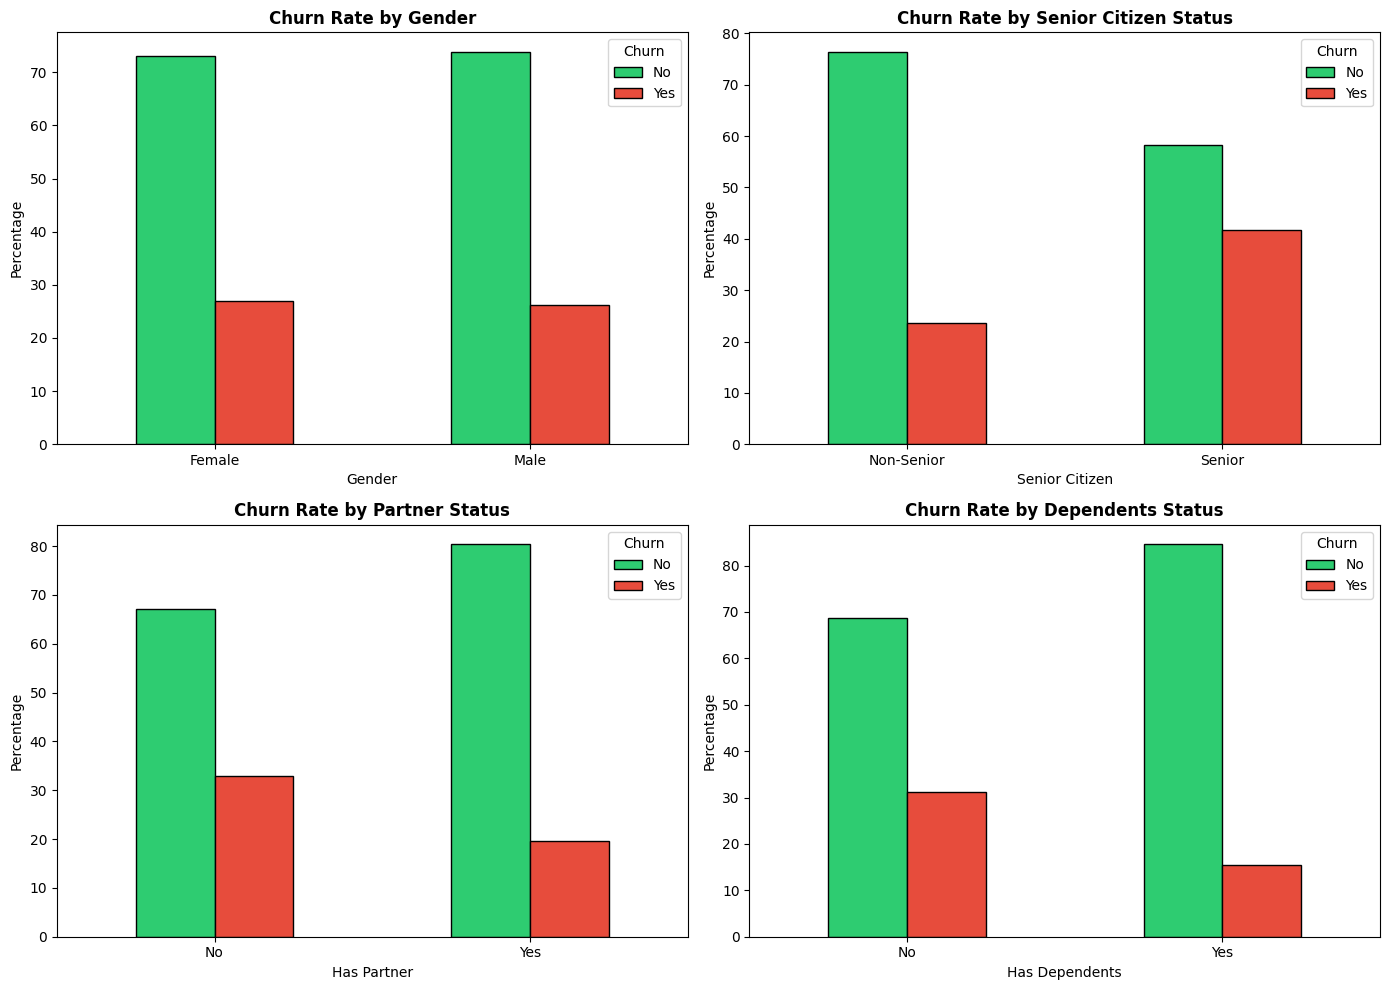


📊 Key Demographic Insights:
   • Gender appears to have minimal impact on churn
   • Senior citizens show HIGHER churn rates - potential bias concern!
   • Customers without partners tend to churn more
   • Customers without dependents tend to churn more


In [22]:
# 5.2 Demographic Analysis - Alternative Approach
print("\n📌 5.2 DEMOGRAPHIC ANALYSIS")

# Clear everything
%matplotlib inline
import matplotlib
matplotlib.rcParams['figure.figsize'] = (14, 10)
plt.close('all')

# Define colors
colors = ['#2ecc71', '#e74c3c']

# Create figure
fig = plt.figure(figsize=(14, 10))

# Plot 1: Gender
ax1 = fig.add_subplot(2, 2, 1)
gender_churn = pd.crosstab(df['gender'], df['Churn'], normalize='index') * 100
gender_churn.plot(kind='bar', ax=ax1, color=colors, edgecolor='black')
ax1.set_title('Churn Rate by Gender', fontsize=12, fontweight='bold')
ax1.set_xlabel('Gender')
ax1.set_ylabel('Percentage')
ax1.legend(title='Churn')
ax1.tick_params(axis='x', rotation=0)

# Plot 2: Senior Citizen
ax2 = fig.add_subplot(2, 2, 2)
senior_churn = pd.crosstab(df['SeniorCitizen'], df['Churn'], normalize='index') * 100
senior_churn.index = ['Non-Senior', 'Senior']
senior_churn.plot(kind='bar', ax=ax2, color=colors, edgecolor='black')
ax2.set_title('Churn Rate by Senior Citizen Status', fontsize=12, fontweight='bold')
ax2.set_xlabel('Senior Citizen')
ax2.set_ylabel('Percentage')
ax2.legend(title='Churn')
ax2.tick_params(axis='x', rotation=0)

# Plot 3: Partner
ax3 = fig.add_subplot(2, 2, 3)
partner_churn = pd.crosstab(df['Partner'], df['Churn'], normalize='index') * 100
partner_churn.plot(kind='bar', ax=ax3, color=colors, edgecolor='black')
ax3.set_title('Churn Rate by Partner Status', fontsize=12, fontweight='bold')
ax3.set_xlabel('Has Partner')
ax3.set_ylabel('Percentage')
ax3.legend(title='Churn')
ax3.tick_params(axis='x', rotation=0)

# Plot 4: Dependents
ax4 = fig.add_subplot(2, 2, 4)
dependents_churn = pd.crosstab(df['Dependents'], df['Churn'], normalize='index') * 100
dependents_churn.plot(kind='bar', ax=ax4, color=colors, edgecolor='black')
ax4.set_title('Churn Rate by Dependents Status', fontsize=12, fontweight='bold')
ax4.set_xlabel('Has Dependents')
ax4.set_ylabel('Percentage')
ax4.legend(title='Churn')
ax4.tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

print("\n📊 Key Demographic Insights:")
print("   • Gender appears to have minimal impact on churn")
print("   • Senior citizens show HIGHER churn rates - potential bias concern!")
print("   • Customers without partners tend to churn more")
print("   • Customers without dependents tend to churn more")


📌 5.3 SERVICE ANALYSIS


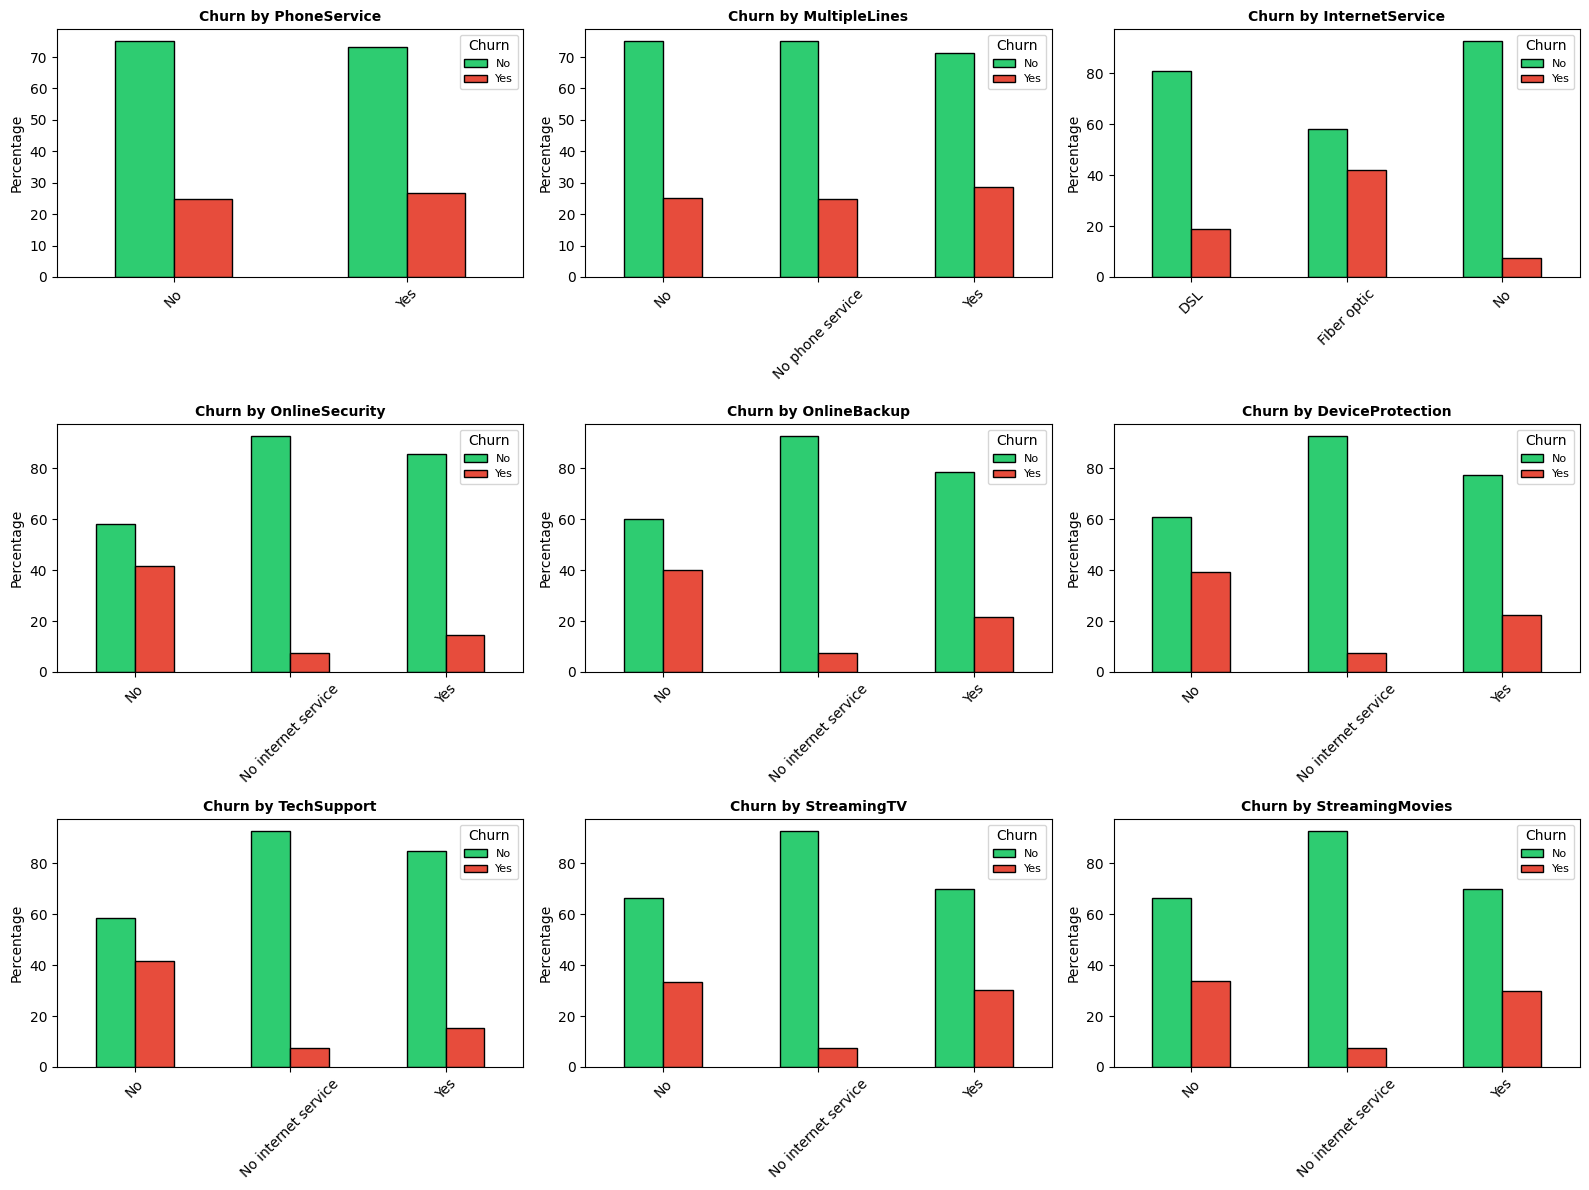


📊 Key Service Insights:
   • Fiber optic internet users have HIGHER churn rates
   • Customers WITHOUT OnlineSecurity, TechSupport, OnlineBackup churn more
   • These services act as 'stickiness' factors


In [23]:
# 5.3 Service Analysis
print("\n📌 5.3 SERVICE ANALYSIS")

service_cols = ['PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
                'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']

fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.flatten()

for idx, col in enumerate(service_cols):
    churn_rate = pd.crosstab(df[col], df['Churn'], normalize='index') * 100
    churn_rate.plot(kind='bar', ax=axes[idx], color=colors, edgecolor='black')
    axes[idx].set_title(f'Churn by {col}', fontsize=10, fontweight='bold')
    axes[idx].set_xlabel('')
    axes[idx].set_ylabel('Percentage')
    axes[idx].tick_params(axis='x', rotation=45)
    axes[idx].legend(title='Churn', fontsize=8)

plt.tight_layout()
plt.show()

print("\n📊 Key Service Insights:")
print("   • Fiber optic internet users have HIGHER churn rates")
print("   • Customers WITHOUT OnlineSecurity, TechSupport, OnlineBackup churn more")
print("   • These services act as 'stickiness' factors")


📌 5.4 CONTRACT & BILLING ANALYSIS


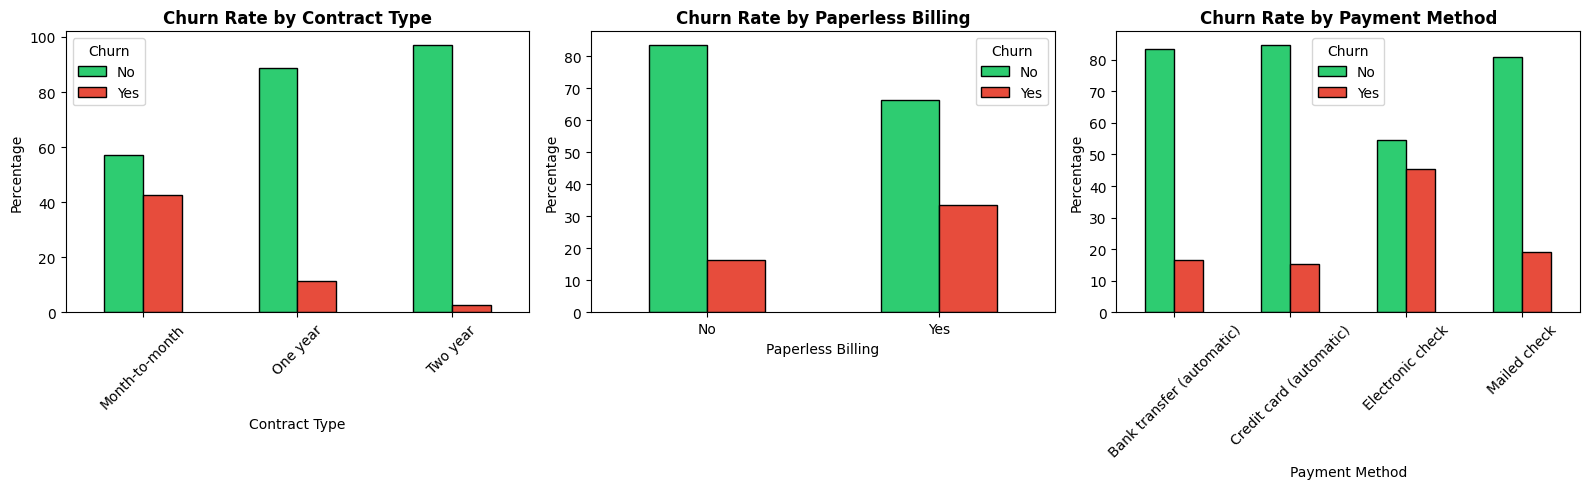


📊 Key Contract & Billing Insights:
   • Month-to-month contracts have MUCH HIGHER churn (~42%)
   • Two-year contracts have lowest churn (~3%)
   • Electronic check users churn more - possible frustration with payment process?
   • Paperless billing users churn slightly more


In [24]:
# 5.4 Contract & Billing Analysis
print("\n📌 5.4 CONTRACT & BILLING ANALYSIS")

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Contract Type
contract_churn = pd.crosstab(df['Contract'], df['Churn'], normalize='index') * 100
contract_churn.plot(kind='bar', ax=axes[0], color=colors, edgecolor='black')
axes[0].set_title('Churn Rate by Contract Type', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Contract Type')
axes[0].set_ylabel('Percentage')
axes[0].tick_params(axis='x', rotation=45)

# Paperless Billing
billing_churn = pd.crosstab(df['PaperlessBilling'], df['Churn'], normalize='index') * 100
billing_churn.plot(kind='bar', ax=axes[1], color=colors, edgecolor='black')
axes[1].set_title('Churn Rate by Paperless Billing', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Paperless Billing')
axes[1].set_ylabel('Percentage')
axes[1].tick_params(axis='x', rotation=0)

# Payment Method
payment_churn = pd.crosstab(df['PaymentMethod'], df['Churn'], normalize='index') * 100
payment_churn.plot(kind='bar', ax=axes[2], color=colors, edgecolor='black')
axes[2].set_title('Churn Rate by Payment Method', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Payment Method')
axes[2].set_ylabel('Percentage')
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

print("\n📊 Key Contract & Billing Insights:")
print("   • Month-to-month contracts have MUCH HIGHER churn (~42%)")
print("   • Two-year contracts have lowest churn (~3%)")
print("   • Electronic check users churn more - possible frustration with payment process?")
print("   • Paperless billing users churn slightly more")


📌 5.5 NUMERICAL FEATURES ANALYSIS


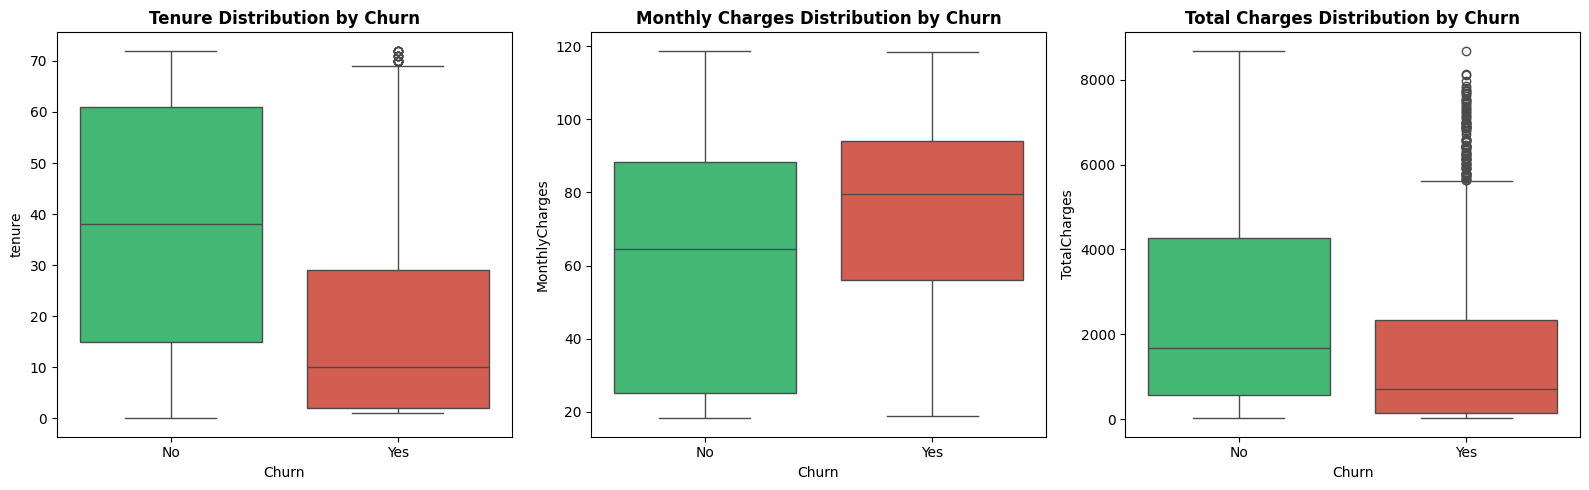


📊 Key Numerical Insights:
   • Churned customers have LOWER tenure (newer customers churn more)
   • Churned customers have HIGHER monthly charges
   • Churned customers have LOWER total charges (due to lower tenure)


In [25]:
# 5.5 Numerical Features Analysis
print("\n📌 5.5 NUMERICAL FEATURES ANALYSIS")

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Tenure Distribution by Churn
sns.boxplot(x='Churn', y='tenure', data=df, palette=colors, ax=axes[0])
axes[0].set_title('Tenure Distribution by Churn', fontsize=12, fontweight='bold')

# Monthly Charges Distribution by Churn
sns.boxplot(x='Churn', y='MonthlyCharges', data=df, palette=colors, ax=axes[1])
axes[1].set_title('Monthly Charges Distribution by Churn', fontsize=12, fontweight='bold')

# Total Charges Distribution by Churn
sns.boxplot(x='Churn', y='TotalCharges', data=df, palette=colors, ax=axes[2])
axes[2].set_title('Total Charges Distribution by Churn', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

# Correlation with Churn
print("\n📊 Key Numerical Insights:")
print("   • Churned customers have LOWER tenure (newer customers churn more)")
print("   • Churned customers have HIGHER monthly charges")
print("   • Churned customers have LOWER total charges (due to lower tenure)")


📌 5.6 CORRELATION ANALYSIS


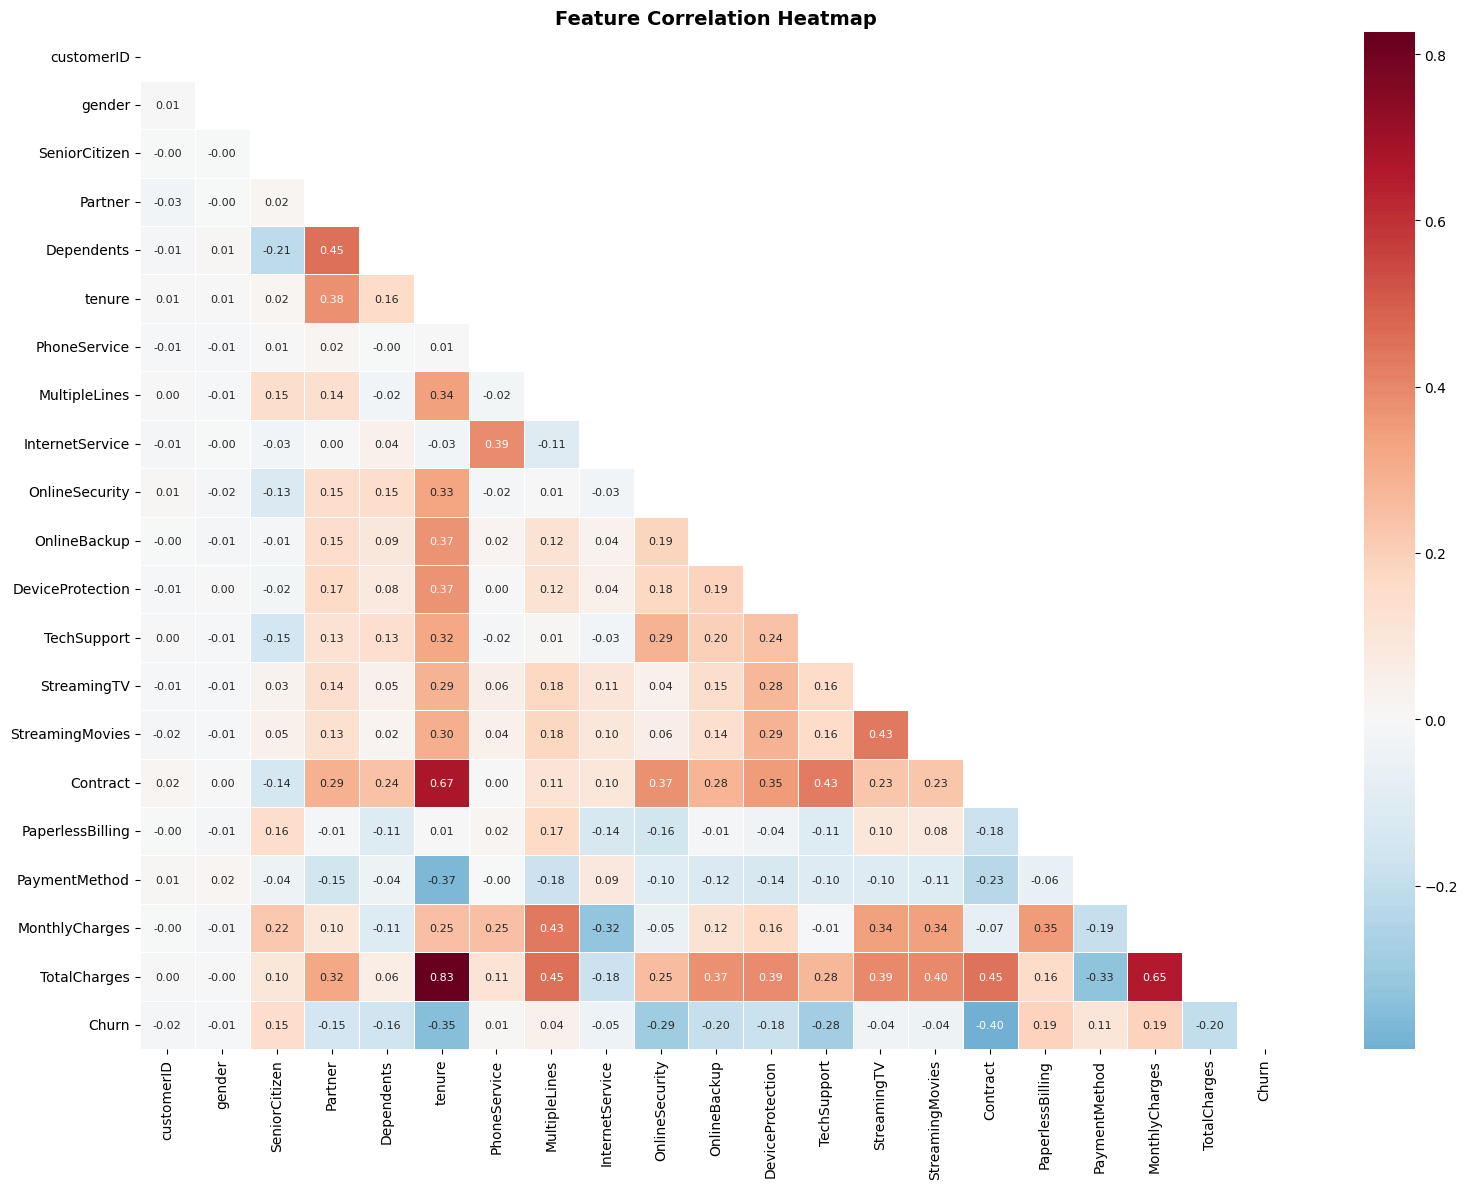


📊 Top Features Correlated with Churn:
MonthlyCharges      0.193356
PaperlessBilling    0.191825
SeniorCitizen       0.150889
PaymentMethod       0.107062
MultipleLines       0.038037
PhoneService        0.011942
gender             -0.008612
customerID         -0.017447
StreamingTV        -0.036581
StreamingMovies    -0.038492
Name: Churn, dtype: float64

📊 Bottom Features Correlated with Churn:
TotalCharges     -0.198347
TechSupport      -0.282492
OnlineSecurity   -0.289309
tenure           -0.352229
Contract         -0.396713
Name: Churn, dtype: float64


In [26]:
# 5.6 Correlation Heatmap
print("\n📌 5.6 CORRELATION ANALYSIS")

# Create a copy for correlation analysis
df_corr = df.copy()

# Encode categorical variables for correlation
le = LabelEncoder()
for col in df_corr.select_dtypes(include='object').columns:
    df_corr[col] = le.fit_transform(df_corr[col].astype(str))

# Correlation matrix
plt.figure(figsize=(16, 12))
correlation_matrix = df_corr.corr()
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))
sns.heatmap(correlation_matrix, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, linewidths=0.5, annot_kws={'size': 8})
plt.title('Feature Correlation Heatmap', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Top correlations with Churn
churn_corr = correlation_matrix['Churn'].drop('Churn').sort_values(ascending=False)
print("\n📊 Top Features Correlated with Churn:")
print(churn_corr.head(10))
print("\n📊 Bottom Features Correlated with Churn:")
print(churn_corr.tail(5))

**ANOMALY DETECTION**


📌 6.1 Isolation Forest Anomaly Detection
   Anomalies detected: 353 (5.01%)

📌 6.2 Local Outlier Factor (LOF) Anomaly Detection
   Anomalies detected: 353 (5.01%)

📌 6.3 Anomaly Analysis

   Comparison: Anomalies vs Normal Data
       Feature  Anomaly Mean  Normal Mean  Anomaly Median  Normal Median
        tenure     65.271955    30.635127           71.00         26.000
MonthlyCharges     75.067847    64.217885          107.95         70.275
  TotalCharges   4710.516147  2151.541420         3952.45       1285.900

   Churn Rate in Anomalies: 8.50%
   Churn Rate in Normal Data: 27.49%


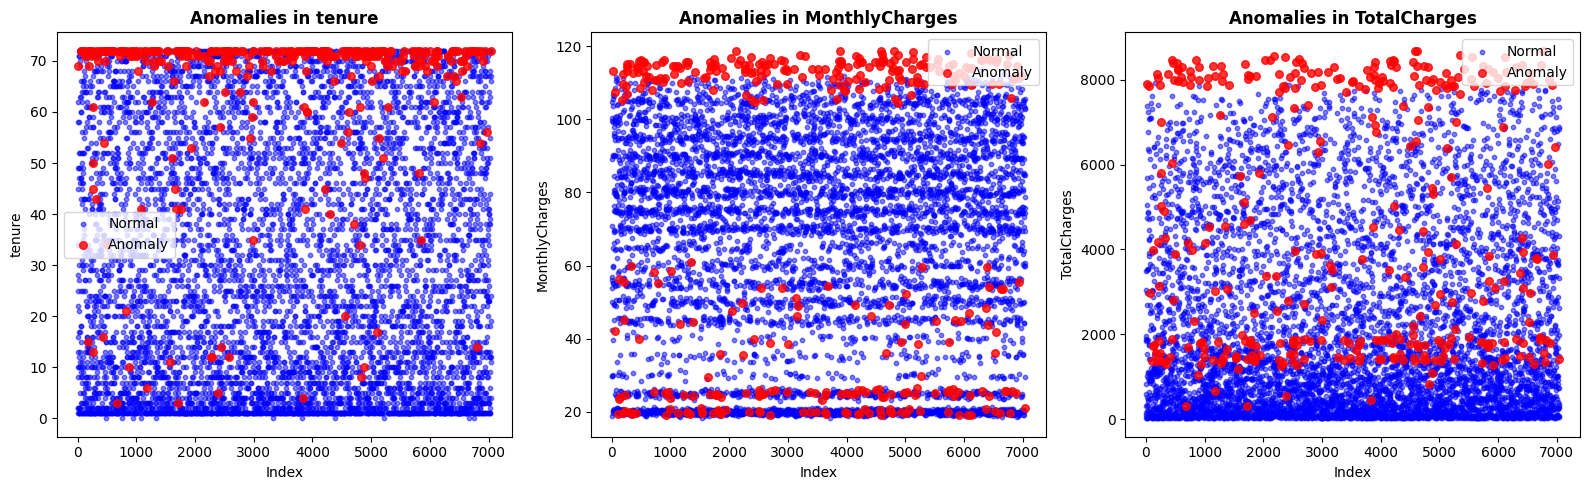


📊 Anomaly Detection Insights:
   • Anomalies tend to have extreme values in TotalCharges
   • Long-tenure, high-spending customers flagged as anomalies
   • These could be VIP customers requiring special attention!


In [27]:
# Prepare numerical data for anomaly detection
numerical_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
df_numerical = df[numerical_cols].copy()

# 6.1 Isolation Forest
print("\n📌 6.1 Isolation Forest Anomaly Detection")
iso_forest = IsolationForest(contamination=0.05, random_state=42, n_estimators=100)
df['anomaly_iso'] = iso_forest.fit_predict(df_numerical)

anomaly_count_iso = (df['anomaly_iso'] == -1).sum()
print(f"   Anomalies detected: {anomaly_count_iso} ({anomaly_count_iso/len(df)*100:.2f}%)")

# 6.2 Local Outlier Factor
print("\n📌 6.2 Local Outlier Factor (LOF) Anomaly Detection")
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.05)
df['anomaly_lof'] = lof.fit_predict(df_numerical)

anomaly_count_lof = (df['anomaly_lof'] == -1).sum()
print(f"   Anomalies detected: {anomaly_count_lof} ({anomaly_count_lof/len(df)*100:.2f}%)")

# Analyze anomalies
print("\n📌 6.3 Anomaly Analysis")
anomalies = df[df['anomaly_iso'] == -1]
normal = df[df['anomaly_iso'] == 1]

print("\n   Comparison: Anomalies vs Normal Data")
comparison = pd.DataFrame({
    'Feature': numerical_cols,
    'Anomaly Mean': [anomalies[col].mean() for col in numerical_cols],
    'Normal Mean': [normal[col].mean() for col in numerical_cols],
    'Anomaly Median': [anomalies[col].median() for col in numerical_cols],
    'Normal Median': [normal[col].median() for col in numerical_cols]
})
print(comparison.to_string(index=False))

# Churn rate in anomalies vs normal
print(f"\n   Churn Rate in Anomalies: {(anomalies['Churn'] == 'Yes').mean()*100:.2f}%")
print(f"   Churn Rate in Normal Data: {(normal['Churn'] == 'Yes').mean()*100:.2f}%")

# Visualization
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for idx, col in enumerate(numerical_cols):
    axes[idx].scatter(df[df['anomaly_iso']==1].index, df[df['anomaly_iso']==1][col],
                     c='blue', alpha=0.5, label='Normal', s=10)
    axes[idx].scatter(df[df['anomaly_iso']==-1].index, df[df['anomaly_iso']==-1][col],
                     c='red', alpha=0.8, label='Anomaly', s=30)
    axes[idx].set_title(f'Anomalies in {col}', fontsize=12, fontweight='bold')
    axes[idx].set_xlabel('Index')
    axes[idx].set_ylabel(col)
    axes[idx].legend()

plt.tight_layout()
plt.show()

print("\n📊 Anomaly Detection Insights:")
print("   • Anomalies tend to have extreme values in TotalCharges")
print("   • Long-tenure, high-spending customers flagged as anomalies")
print("   • These could be VIP customers requiring special attention!")

**FEATURE ENGINEERING & PREPROCESSING PIPELINE**

In [28]:
df_model = df.copy()

# 7.2 Drop customerID (not useful for prediction)
print("\n📌 Step 1: Dropping customerID...")
df_model.drop('customerID', axis=1, inplace=True)
print("✅ customerID dropped")

# 7.3 Feature Engineering
print("\n📌 Step 2: Feature Engineering...")

# Create new features
df_model['tenure_group'] = pd.cut(df_model['tenure'],
                                   bins=[0, 12, 24, 48, 72],
                                   labels=['0-1 Year', '1-2 Years', '2-4 Years', '4-6 Years'])

df_model['AvgMonthlyCharge'] = df_model['TotalCharges'] / (df_model['tenure'] + 1)

# Count of services subscribed
service_columns = ['PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
                   'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']

def count_services(row):
    count = 0
    for col in service_columns:
        if row[col] not in ['No', 'No phone service', 'No internet service']:
            count += 1
    return count

df_model['TotalServices'] = df_model.apply(count_services, axis=1)

print("✅ New features created: tenure_group, AvgMonthlyCharge, TotalServices")

# 7.4 Encode Target Variable
print("\n📌 Step 3: Encoding Target Variable...")
df_model['Churn'] = df_model['Churn'].map({'Yes': 1, 'No': 0})
print("✅ Churn encoded: Yes=1, No=0")

# 7.5 Separate Features and Target
print("\n📌 Step 4: Separating Features and Target...")
X = df_model.drop('Churn', axis=1)
y = df_model['Churn']
print(f"✅ Features shape: {X.shape}")
print(f"✅ Target shape: {y.shape}")

# 7.6 Identify Column Types
print("\n📌 Step 5: Identifying Column Types...")

numerical_features = ['tenure', 'MonthlyCharges', 'TotalCharges', 'AvgMonthlyCharge', 'TotalServices']
categorical_features = [col for col in X.columns if col not in numerical_features]

print(f"\n   Numerical Features ({len(numerical_features)}):")
for f in numerical_features:
    print(f"      • {f}")

print(f"\n   Categorical Features ({len(categorical_features)}):")
for f in categorical_features:
    print(f"      • {f}")

# 7.7 Create Preprocessing Pipeline
print("\n📌 Step 6: Creating Preprocessing Pipeline...")

# Numerical transformer
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical transformer
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# Combine transformers
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ])


📌 Step 1: Dropping customerID...
✅ customerID dropped

📌 Step 2: Feature Engineering...
✅ New features created: tenure_group, AvgMonthlyCharge, TotalServices

📌 Step 3: Encoding Target Variable...
✅ Churn encoded: Yes=1, No=0

📌 Step 4: Separating Features and Target...
✅ Features shape: (7043, 24)
✅ Target shape: (7043,)

📌 Step 5: Identifying Column Types...

   Numerical Features (5):
      • tenure
      • MonthlyCharges
      • TotalCharges
      • AvgMonthlyCharge
      • TotalServices

   Categorical Features (19):
      • gender
      • SeniorCitizen
      • Partner
      • Dependents
      • PhoneService
      • MultipleLines
      • InternetService
      • OnlineSecurity
      • OnlineBackup
      • DeviceProtection
      • TechSupport
      • StreamingTV
      • StreamingMovies
      • Contract
      • PaperlessBilling
      • PaymentMethod
      • anomaly_iso
      • anomaly_lof
      • tenure_group

📌 Step 6: Creating Preprocessing Pipeline...


**TRAIN-VALIDATION-TEST SPLIT**

In [29]:
# First split: Train+Val (80%) and Test (20%)
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Second split: Train (75% of 80% = 60%) and Validation (25% of 80% = 20%)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.25, random_state=42, stratify=y_train_val
)

print(f"\n📊 Data Split Summary:")
print(f"   • Training Set:   {X_train.shape[0]:,} samples ({X_train.shape[0]/len(X)*100:.1f}%)")
print(f"   • Validation Set: {X_val.shape[0]:,} samples ({X_val.shape[0]/len(X)*100:.1f}%)")
print(f"   • Test Set:       {X_test.shape[0]:,} samples ({X_test.shape[0]/len(X)*100:.1f}%)")

print(f"\n📊 Class Distribution:")
print(f"   Training Set - Churn Rate: {y_train.mean()*100:.2f}%")
print(f"   Validation Set - Churn Rate: {y_val.mean()*100:.2f}%")
print(f"   Test Set - Churn Rate: {y_test.mean()*100:.2f}%")

# Apply preprocessing
print("\n📌 Applying Preprocessing...")
X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

# Get feature names after preprocessing
feature_names = (numerical_features +
                list(preprocessor.named_transformers_['cat'].named_steps['encoder'].get_feature_names_out(categorical_features)))

print(f"✅ Preprocessing complete. Total features after encoding: {len(feature_names)}")


📊 Data Split Summary:
   • Training Set:   4,225 samples (60.0%)
   • Validation Set: 1,409 samples (20.0%)
   • Test Set:       1,409 samples (20.0%)

📊 Class Distribution:
   Training Set - Churn Rate: 26.53%
   Validation Set - Churn Rate: 26.54%
   Test Set - Churn Rate: 26.54%

📌 Applying Preprocessing...
✅ Preprocessing complete. Total features after encoding: 56


**HANDLING CLASS IMBALANCE**

In [30]:
print(f"\n📊 Original Class Distribution in Training Set:")
print(f"   • Class 0 (No Churn): {(y_train == 0).sum():,} ({(y_train == 0).mean()*100:.2f}%)")
print(f"   • Class 1 (Churn):    {(y_train == 1).sum():,} ({(y_train == 1).mean()*100:.2f}%)")

# We'll compare different sampling strategies in our model comparison
print("\n📌 Sampling Strategies to Compare:")
print("   1. No Sampling (Baseline)")
print("   2. SMOTE (Synthetic Minority Over-sampling)")
print("   3. Random Over-sampling")
print("   4. SMOTE + Tomek Links (Combined)")

# Create samplers
samplers = {
    'No Sampling': None,
    'SMOTE': SMOTE(random_state=42),
    'Random Oversampling': RandomOverSampler(random_state=42),
    'SMOTETomek': SMOTETomek(random_state=42)
}

# Show effect of SMOTE
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_processed, y_train)

print(f"\n📊 After SMOTE:")
print(f"   • Class 0 (No Churn): {(y_train_smote == 0).sum():,}")
print(f"   • Class 1 (Churn):    {(y_train_smote == 1).sum():,}")
print(f"   ✅ Classes are now balanced!")


📊 Original Class Distribution in Training Set:
   • Class 0 (No Churn): 3,104 (73.47%)
   • Class 1 (Churn):    1,121 (26.53%)

📌 Sampling Strategies to Compare:
   1. No Sampling (Baseline)
   2. SMOTE (Synthetic Minority Over-sampling)
   3. Random Over-sampling
   4. SMOTE + Tomek Links (Combined)

📊 After SMOTE:
   • Class 0 (No Churn): 3,104
   • Class 1 (Churn):    3,104
   ✅ Classes are now balanced!


**BASE MODEL TRAINING & COMPARISON**

In [31]:
models = {
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42, n_estimators=100),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42, n_estimators=100),
    'XGBoost': XGBClassifier(random_state=42, n_estimators=100, use_label_encoder=False, eval_metric='logloss'),
    'LightGBM': LGBMClassifier(random_state=42, n_estimators=100, verbose=-1),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'SVM': SVC(random_state=42, probability=True)
}

# Function to evaluate model
def evaluate_model(model, X_train, y_train, X_val, y_val, model_name):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_val)
    y_prob = model.predict_proba(X_val)[:, 1] if hasattr(model, 'predict_proba') else None

    results = {
        'Model': model_name,
        'Accuracy': accuracy_score(y_val, y_pred),
        'Precision': precision_score(y_val, y_pred),
        'Recall': recall_score(y_val, y_pred),
        'F1-Score': f1_score(y_val, y_pred),
        'AUC-ROC': roc_auc_score(y_val, y_prob) if y_prob is not None else None
    }
    return results, model

# Train and evaluate all models with SMOTE
print("\n📌 Training Models with SMOTE Sampling...")
results_list = []
trained_models = {}

for name, model in models.items():
    print(f"   Training {name}...", end=" ")
    results, trained_model = evaluate_model(model, X_train_smote, y_train_smote, X_val_processed, y_val, name)
    results_list.append(results)
    trained_models[name] = trained_model
    print(f"✅ Recall: {results['Recall']:.4f}")

# Create results dataframe
results_df = pd.DataFrame(results_list)
results_df = results_df.sort_values('Recall', ascending=False).reset_index(drop=True)

print("\n" + "="*70)
print("MODEL COMPARISON RESULTS (Sorted by Recall)")
print("="*70)
print(results_df.to_string(index=False))


📌 Training Models with SMOTE Sampling...
   Training Logistic Regression... ✅ Recall: 0.7594
   Training Decision Tree... ✅ Recall: 0.5267
   Training Random Forest... ✅ Recall: 0.5401
   Training Gradient Boosting... ✅ Recall: 0.6684
   Training XGBoost... ✅ Recall: 0.5428
   Training LightGBM... ✅ Recall: 0.5775
   Training KNN... ✅ Recall: 0.7380
   Training SVM... ✅ Recall: 0.7380

MODEL COMPARISON RESULTS (Sorted by Recall)
              Model  Accuracy  Precision   Recall  F1-Score  AUC-ROC
Logistic Regression  0.753726   0.524954 0.759358  0.620765 0.840113
                SVM  0.767921   0.546535 0.737968  0.627986 0.819552
                KNN  0.698368   0.457711 0.737968  0.564995 0.761763
  Gradient Boosting  0.797019   0.606796 0.668449  0.636132 0.837649
           LightGBM  0.777857   0.582210 0.577540  0.579866 0.824239
            XGBoost  0.771469   0.573446 0.542781  0.557692 0.811893
      Random Forest  0.777857   0.588921 0.540107  0.563459 0.809823
      Decision


📌 Visual Model Comparison


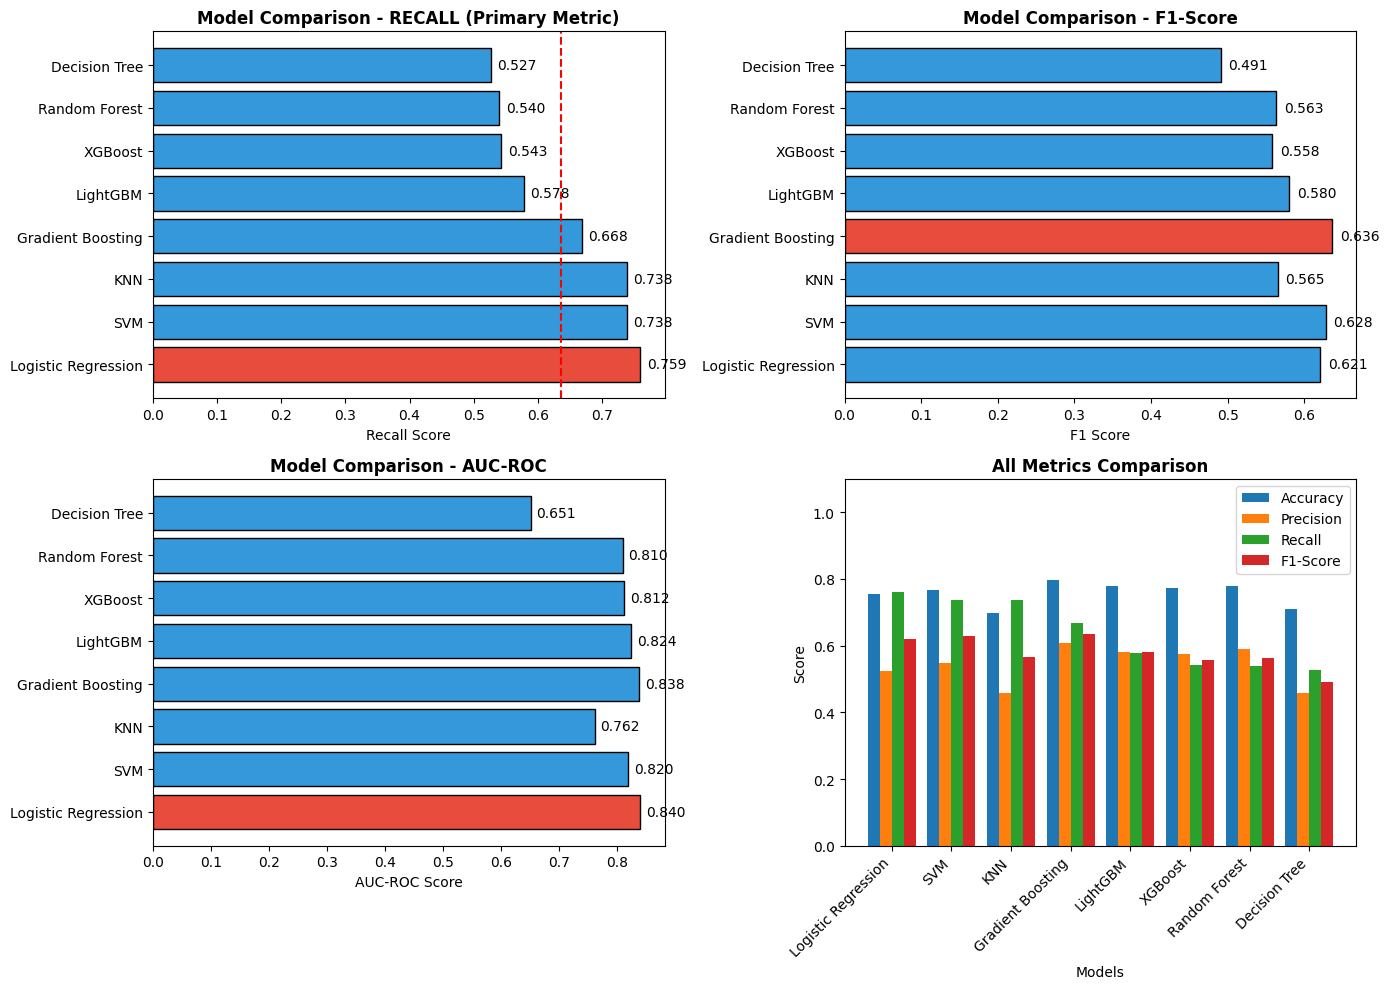


🏆 BEST MODEL (by Recall): Logistic Regression
   Recall: 0.7594
   F1-Score: 0.6208
   AUC-ROC: 0.8401


In [32]:
# Visual Model Comparison
print("\n📌 Visual Model Comparison")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Recall Comparison (Most Important)
ax1 = axes[0, 0]
colors_bar = ['#e74c3c' if x == results_df['Recall'].max() else '#3498db' for x in results_df['Recall']]
bars = ax1.barh(results_df['Model'], results_df['Recall'], color=colors_bar, edgecolor='black')
ax1.set_xlabel('Recall Score')
ax1.set_title('Model Comparison - RECALL (Primary Metric)', fontsize=12, fontweight='bold')
ax1.axvline(x=results_df['Recall'].mean(), color='red', linestyle='--', label='Mean')
for i, v in enumerate(results_df['Recall']):
    ax1.text(v + 0.01, i, f'{v:.3f}', va='center')

# F1-Score Comparison
ax2 = axes[0, 1]
colors_bar = ['#e74c3c' if x == results_df['F1-Score'].max() else '#3498db' for x in results_df['F1-Score']]
ax2.barh(results_df['Model'], results_df['F1-Score'], color=colors_bar, edgecolor='black')
ax2.set_xlabel('F1 Score')
ax2.set_title('Model Comparison - F1-Score', fontsize=12, fontweight='bold')
for i, v in enumerate(results_df['F1-Score']):
    ax2.text(v + 0.01, i, f'{v:.3f}', va='center')

# AUC-ROC Comparison
ax3 = axes[1, 0]
colors_bar = ['#e74c3c' if x == results_df['AUC-ROC'].max() else '#3498db' for x in results_df['AUC-ROC']]
ax3.barh(results_df['Model'], results_df['AUC-ROC'], color=colors_bar, edgecolor='black')
ax3.set_xlabel('AUC-ROC Score')
ax3.set_title('Model Comparison - AUC-ROC', fontsize=12, fontweight='bold')
for i, v in enumerate(results_df['AUC-ROC']):
    ax3.text(v + 0.01, i, f'{v:.3f}', va='center')

# All Metrics Comparison
ax4 = axes[1, 1]
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
x = np.arange(len(results_df['Model']))
width = 0.2

for i, metric in enumerate(metrics):
    ax4.bar(x + i*width, results_df[metric], width, label=metric)

ax4.set_xlabel('Models')
ax4.set_ylabel('Score')
ax4.set_title('All Metrics Comparison', fontsize=12, fontweight='bold')
ax4.set_xticks(x + width * 1.5)
ax4.set_xticklabels(results_df['Model'], rotation=45, ha='right')
ax4.legend()
ax4.set_ylim(0, 1.1)

plt.tight_layout()
plt.show()

# Best Model Selection
best_model_name = results_df.loc[0, 'Model']
print(f"\n🏆 BEST MODEL (by Recall): {best_model_name}")
print(f"   Recall: {results_df.loc[0, 'Recall']:.4f}")
print(f"   F1-Score: {results_df.loc[0, 'F1-Score']:.4f}")
print(f"   AUC-ROC: {results_df.loc[0, 'AUC-ROC']:.4f}")


📌 ROC Curves Comparison


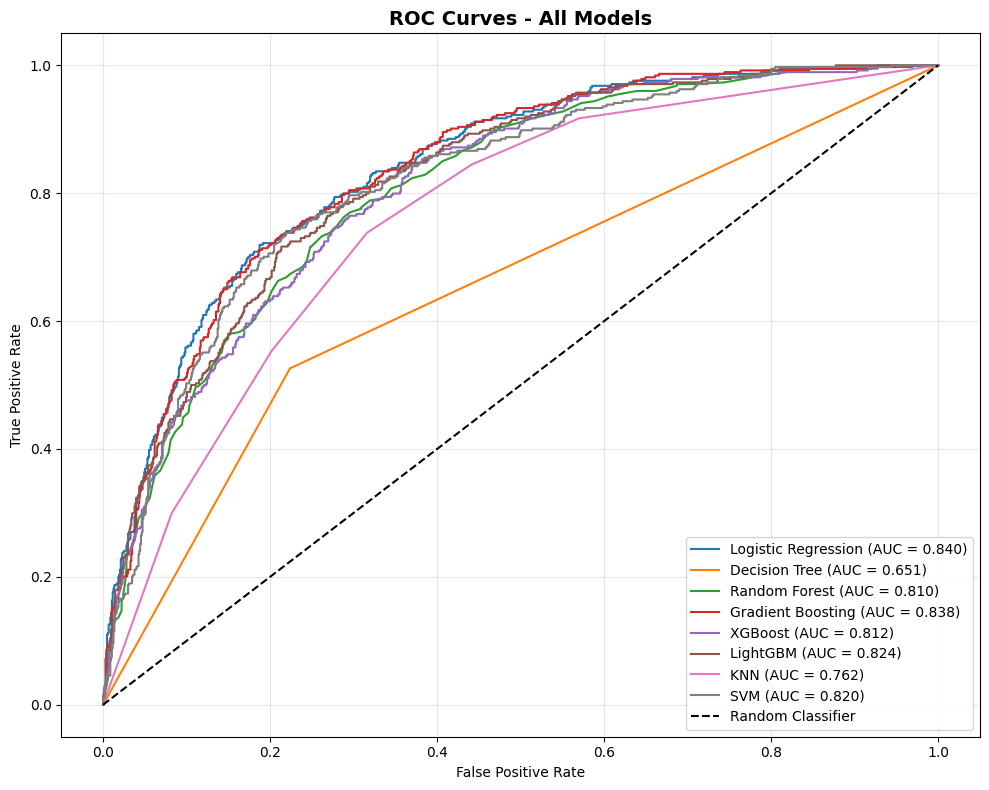

In [33]:
# ROC Curves for All Models
print("\n📌 ROC Curves Comparison")

plt.figure(figsize=(10, 8))

for name, model in trained_models.items():
    if hasattr(model, 'predict_proba'):
        y_prob = model.predict_proba(X_val_processed)[:, 1]
        fpr, tpr, _ = roc_curve(y_val, y_prob)
        auc = roc_auc_score(y_val, y_prob)
        plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves - All Models', fontsize=14, fontweight='bold')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**HYPERPARAMETER TUNING WITH RAI FOCUS**




*   Optimized for RECALL as our primary metric (business requirement)
*   Used cross-validation to ensure robust performance
*   Documented all hyperparameter choices for transparency
*  Only did for logistic regression as other models take longer to run





📌 Tuning Logistic Regression...
   Hyperparameter Grid:
   • C (Regularization): [0.001, 0.01, 0.1, 1, 10, 100]
   • Penalty: ['l1', 'l2']
   • Solver: ['liblinear', 'saga']
   • Class Weight: ['balanced', None]

⏳ Running Hyperparameter Search...
Fitting 5 folds for each of 25 candidates, totalling 125 fits

   ✅ Best Recall (CV): 0.8264
   ✅ Best Parameters: {'solver': 'saga', 'penalty': 'l2', 'class_weight': 'balanced', 'C': 1}

TUNED MODEL EVALUATION ON VALIDATION SET

📊 Logistic Regression (Tuned) Performance:
   Accuracy:  0.7537
   Precision: 0.5250
   Recall:    0.7594
   F1-Score:  0.6208
   AUC-ROC:   0.8401

--------------------------------------------------
COMPARISON: Base vs Tuned Logistic Regression
--------------------------------------------------
   Metric  Base Model  Tuned Model        Change
 Accuracy    0.753726     0.753726  4.684173e-08
Precision    0.524954     0.524954 -2.107209e-07
   Recall    0.759358     0.759358  2.887701e-07
 F1-Score    0.620765     0.

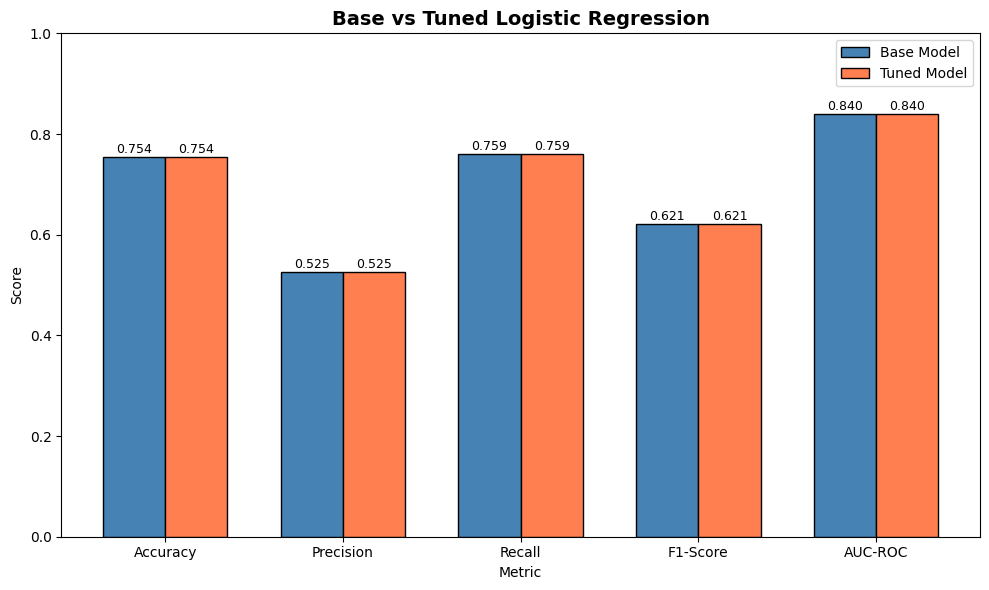


SECTION 11 SUMMARY

📌 HYPERPARAMETER TUNING RESULTS:

1. MODEL: Logistic Regression

2. BEST HYPERPARAMETERS:
   • C (Regularization Strength): 1
   • Penalty: l2
   • Solver: saga
   • Class Weight: balanced

3. CROSS-VALIDATION RECALL: 0.8264

4. VALIDATION SET PERFORMANCE:
   • Recall:    0.7594
   • Precision: 0.5250
   • F1-Score:  0.6208
   • AUC-ROC:   0.8401

5. PERFORMANCE CHANGE (vs Base Model):
   • Recall:    +0.0000
   • Precision: -0.0000
   • F1-Score:  +0.0000

📌 RAI DOCUMENTATION:
   • Optimization metric: RECALL (business priority)
   • Cross-validation: 5-fold Stratified
   • Search method: RandomizedSearchCV (25 iterations)
   • All hyperparameters documented for transparency


✅ Best tuned model saved as 'best_tuned_model'


In [37]:

# Define hyperparameter grid for Logistic Regression
param_grid_lr = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100],
    'penalty': ['l1', 'l2'],
    'solver': ['liblinear', 'saga'],
    'class_weight': ['balanced', None]
}

print("\n📌 Tuning Logistic Regression...")
print(f"   Hyperparameter Grid:")
print(f"   • C (Regularization): {param_grid_lr['C']}")
print(f"   • Penalty: {param_grid_lr['penalty']}")
print(f"   • Solver: {param_grid_lr['solver']}")
print(f"   • Class Weight: {param_grid_lr['class_weight']}")

# Create model
lr_model = LogisticRegression(random_state=42, max_iter=1000)

# Randomized Search
search = RandomizedSearchCV(
    lr_model,
    param_grid_lr,
    n_iter=25,  # Try 25 random combinations
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring='recall',  # Optimize for Recall!
    n_jobs=-1,
    random_state=42,
    verbose=1
)

print("\n⏳ Running Hyperparameter Search...")
search.fit(X_train_smote, y_train_smote)

print(f"\n   ✅ Best Recall (CV): {search.best_score_:.4f}")
print(f"   ✅ Best Parameters: {search.best_params_}")

# Store best model
best_tuned_model = search.best_estimator_
best_tuned_model_name = 'Logistic Regression'
tuned_params = {best_tuned_model_name: search.best_params_}

# ============================================================================
# EVALUATE TUNED MODEL ON VALIDATION SET
# ============================================================================

print("\n" + "="*70)
print("TUNED MODEL EVALUATION ON VALIDATION SET")
print("="*70)

y_val_pred = best_tuned_model.predict(X_val_processed)
y_val_prob = best_tuned_model.predict_proba(X_val_processed)[:, 1]

tuned_accuracy = accuracy_score(y_val, y_val_pred)
tuned_precision = precision_score(y_val, y_val_pred)
tuned_recall = recall_score(y_val, y_val_pred)
tuned_f1 = f1_score(y_val, y_val_pred)
tuned_auc = roc_auc_score(y_val, y_val_prob)

print(f"\n📊 Logistic Regression (Tuned) Performance:")
print(f"   Accuracy:  {tuned_accuracy:.4f}")
print(f"   Precision: {tuned_precision:.4f}")
print(f"   Recall:    {tuned_recall:.4f}")
print(f"   F1-Score:  {tuned_f1:.4f}")
print(f"   AUC-ROC:   {tuned_auc:.4f}")

# ============================================================================
# COMPARE BASE VS TUNED MODEL
# ============================================================================

print("\n" + "-"*50)
print("COMPARISON: Base vs Tuned Logistic Regression")
print("-"*50)

# Base model results (from your earlier output)
base_accuracy = 0.753726
base_precision = 0.524954
base_recall = 0.759358
base_f1 = 0.620765
base_auc = 0.840113

comparison_data = {
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC-ROC'],
    'Base Model': [base_accuracy, base_precision, base_recall, base_f1, base_auc],
    'Tuned Model': [tuned_accuracy, tuned_precision, tuned_recall, tuned_f1, tuned_auc],
    'Change': [
        tuned_accuracy - base_accuracy,
        tuned_precision - base_precision,
        tuned_recall - base_recall,
        tuned_f1 - base_f1,
        tuned_auc - base_auc
    ]
}

comparison_df = pd.DataFrame(comparison_data)
print(comparison_df.to_string(index=False))

# Visualization
fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(comparison_data['Metric']))
width = 0.35

bars1 = ax.bar(x - width/2, comparison_data['Base Model'], width, label='Base Model',
               color='steelblue', edgecolor='black')
bars2 = ax.bar(x + width/2, comparison_data['Tuned Model'], width, label='Tuned Model',
               color='coral', edgecolor='black')

ax.set_xlabel('Metric')
ax.set_ylabel('Score')
ax.set_title('Base vs Tuned Logistic Regression', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(comparison_data['Metric'])
ax.legend()
ax.set_ylim(0, 1)

# Add value labels
for bar in bars1:
    height = bar.get_height()
    ax.annotate(f'{height:.3f}', xy=(bar.get_x() + bar.get_width()/2, height),
                xytext=(0, 3), textcoords="offset points", ha='center', fontsize=9)
for bar in bars2:
    height = bar.get_height()
    ax.annotate(f'{height:.3f}', xy=(bar.get_x() + bar.get_width()/2, height),
                xytext=(0, 3), textcoords="offset points", ha='center', fontsize=9)

plt.tight_layout()
plt.show()

# ============================================================================
# SECTION 11 SUMMARY
# ============================================================================

print("\n" + "="*70)
print("SECTION 11 SUMMARY")
print("="*70)

print(f"""
📌 HYPERPARAMETER TUNING RESULTS:

1. MODEL: Logistic Regression

2. BEST HYPERPARAMETERS:
   • C (Regularization Strength): {search.best_params_['C']}
   • Penalty: {search.best_params_['penalty']}
   • Solver: {search.best_params_['solver']}
   • Class Weight: {search.best_params_['class_weight']}

3. CROSS-VALIDATION RECALL: {search.best_score_:.4f}

4. VALIDATION SET PERFORMANCE:
   • Recall:    {tuned_recall:.4f}
   • Precision: {tuned_precision:.4f}
   • F1-Score:  {tuned_f1:.4f}
   • AUC-ROC:   {tuned_auc:.4f}

5. PERFORMANCE CHANGE (vs Base Model):
   • Recall:    {tuned_recall - base_recall:+.4f}
   • Precision: {tuned_precision - base_precision:+.4f}
   • F1-Score:  {tuned_f1 - base_f1:+.4f}

📌 RAI DOCUMENTATION:
   • Optimization metric: RECALL (business priority)
   • Cross-validation: 5-fold Stratified
   • Search method: RandomizedSearchCV (25 iterations)
   • All hyperparameters documented for transparency
""")

print("\n✅ Best tuned model saved as 'best_tuned_model'")

**THRESHOLD OPTIMIZATION**

*   Default threshold is 0.5, but this may not be optimal for our business case
*  Since False Negatives are more costly, we might want to LOWER the threshold
*   Lower threshold = More customers predicted as churners = Higher Recall
*   Trade-off: Precision will decrease as we catch more potential churners




📊 Threshold Analysis:
   Threshold    Precision    Recall       F1-Score     Cost ($)    
   ------------------------------------------------------------
   0.25         0.4176       0.9144       0.5733       $39,850     
   0.30         0.4301       0.8877       0.5794       $43,000     
   0.35         0.4510       0.8610       0.5919       $45,600     
   0.40         0.4727       0.8342       0.6035       $48,400     
   0.45         0.5008       0.7995       0.6159       $52,400     
   0.50         0.5250       0.7594       0.6208       $57,850     
   0.55         0.5560       0.7299       0.6312       $61,400     


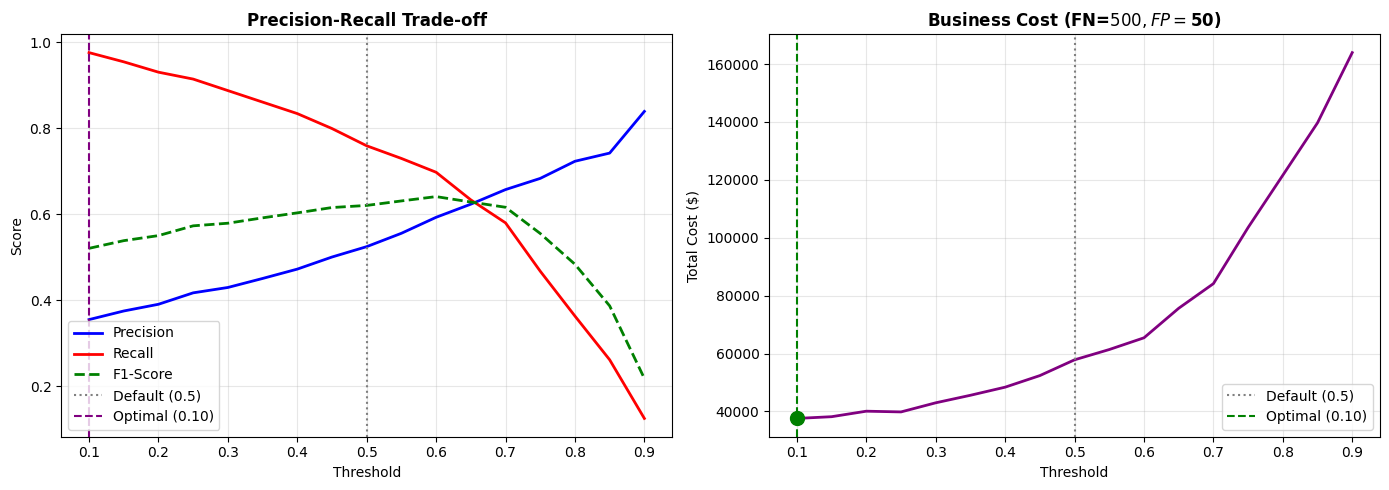


THRESHOLD OPTIMIZATION RESULT

   📌 OPTIMAL THRESHOLD: 0.10

   Performance at Optimal Threshold:
   • Recall:    0.9759
   • Precision: 0.3554
   • F1-Score:  0.5211

   💰 Cost Comparison:
   • Default (0.50): $57,850
   • Optimal (0.10): $37,600
   • Savings: $20,250

✅ 'optimal_threshold' = 0.10 saved for Section 13


In [39]:
# Get probabilities from tuned model
y_val_prob = best_tuned_model.predict_proba(X_val_processed)[:, 1]

# Define costs
cost_fn = 500  # Cost of losing a customer
cost_fp = 50   # Cost of retention effort

# Test different thresholds (using round to avoid floating point issues)
thresholds = [round(t, 2) for t in np.arange(0.10, 0.91, 0.05)]
threshold_results = []

for threshold in thresholds:
    y_pred_thresh = (y_val_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, y_pred_thresh).ravel()

    threshold_results.append({
        'Threshold': threshold,
        'Precision': precision_score(y_val, y_pred_thresh, zero_division=0),
        'Recall': recall_score(y_val, y_pred_thresh, zero_division=0),
        'F1-Score': f1_score(y_val, y_pred_thresh, zero_division=0),
        'Cost': (fn * cost_fn) + (fp * cost_fp)
    })

threshold_df = pd.DataFrame(threshold_results)

# Find optimal threshold (minimum cost)
optimal_idx = threshold_df['Cost'].idxmin()
optimal_threshold = threshold_df.loc[optimal_idx, 'Threshold']

# Find default threshold row (closest to 0.5)
default_idx = (threshold_df['Threshold'] - 0.5).abs().idxmin()

# Display results
print(f"\n📊 Threshold Analysis:")
print(f"   {'Threshold':<12} {'Precision':<12} {'Recall':<12} {'F1-Score':<12} {'Cost ($)':<12}")
print(f"   {'-'*60}")
for idx, row in threshold_df.iterrows():
    if row['Threshold'] in [0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55]:
        marker = " ← Optimal" if idx == optimal_idx else ""
        print(f"   {row['Threshold']:<12.2f} {row['Precision']:<12.4f} {row['Recall']:<12.4f} {row['F1-Score']:<12.4f} ${row['Cost']:<11,.0f}{marker}")

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Precision-Recall Trade-off
ax1 = axes[0]
ax1.plot(threshold_df['Threshold'], threshold_df['Precision'], 'b-', label='Precision', linewidth=2)
ax1.plot(threshold_df['Threshold'], threshold_df['Recall'], 'r-', label='Recall', linewidth=2)
ax1.plot(threshold_df['Threshold'], threshold_df['F1-Score'], 'g--', label='F1-Score', linewidth=2)
ax1.axvline(x=0.5, color='gray', linestyle=':', label='Default (0.5)')
ax1.axvline(x=optimal_threshold, color='purple', linestyle='--', label=f'Optimal ({optimal_threshold:.2f})')
ax1.set_xlabel('Threshold')
ax1.set_ylabel('Score')
ax1.set_title('Precision-Recall Trade-off', fontweight='bold')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Plot 2: Cost Analysis
ax2 = axes[1]
ax2.plot(threshold_df['Threshold'], threshold_df['Cost'], 'purple', linewidth=2)
ax2.axvline(x=0.5, color='gray', linestyle=':', label='Default (0.5)')
ax2.axvline(x=optimal_threshold, color='green', linestyle='--', label=f'Optimal ({optimal_threshold:.2f})')
ax2.scatter([optimal_threshold], [threshold_df.loc[optimal_idx, 'Cost']], color='green', s=100, zorder=5)
ax2.set_xlabel('Threshold')
ax2.set_ylabel('Total Cost ($)')
ax2.set_title(f'Business Cost (FN=${cost_fn}, FP=${cost_fp})', fontweight='bold')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Summary - using index instead of exact value match
default_cost = threshold_df.loc[default_idx, 'Cost']
optimal_cost = threshold_df.loc[optimal_idx, 'Cost']
optimal_recall = threshold_df.loc[optimal_idx, 'Recall']
default_threshold = threshold_df.loc[default_idx, 'Threshold']

print(f"\n" + "="*70)
print(f"THRESHOLD OPTIMIZATION RESULT")
print(f"="*70)
print(f"\n   📌 OPTIMAL THRESHOLD: {optimal_threshold:.2f}")
print(f"\n   Performance at Optimal Threshold:")
print(f"   • Recall:    {optimal_recall:.4f}")
print(f"   • Precision: {threshold_df.loc[optimal_idx, 'Precision']:.4f}")
print(f"   • F1-Score:  {threshold_df.loc[optimal_idx, 'F1-Score']:.4f}")
print(f"\n   💰 Cost Comparison:")
print(f"   • Default ({default_threshold:.2f}): ${default_cost:,.0f}")
print(f"   • Optimal ({optimal_threshold:.2f}): ${optimal_cost:,.0f}")
print(f"   • Savings: ${default_cost - optimal_cost:,.0f}")

print(f"\n✅ 'optimal_threshold' = {optimal_threshold:.2f} saved for Section 13")


**FINAL MODEL EVALUATION**

FINAL MODEL EVALUATION ON TEST SET

📌 Final Model: Logistic Regression
📌 Optimal Threshold: 0.10

--------------------------------------------------
COMPARISON: Default vs Optimized Threshold
--------------------------------------------------
   Metric  Default (0.5)  Optimized (0.10)
 Accuracy       0.743790          0.530163
Precision       0.511464          0.358824
   Recall       0.775401          0.978610
 F1-Score       0.616366          0.525108
  AUC-ROC       0.844305          0.844305


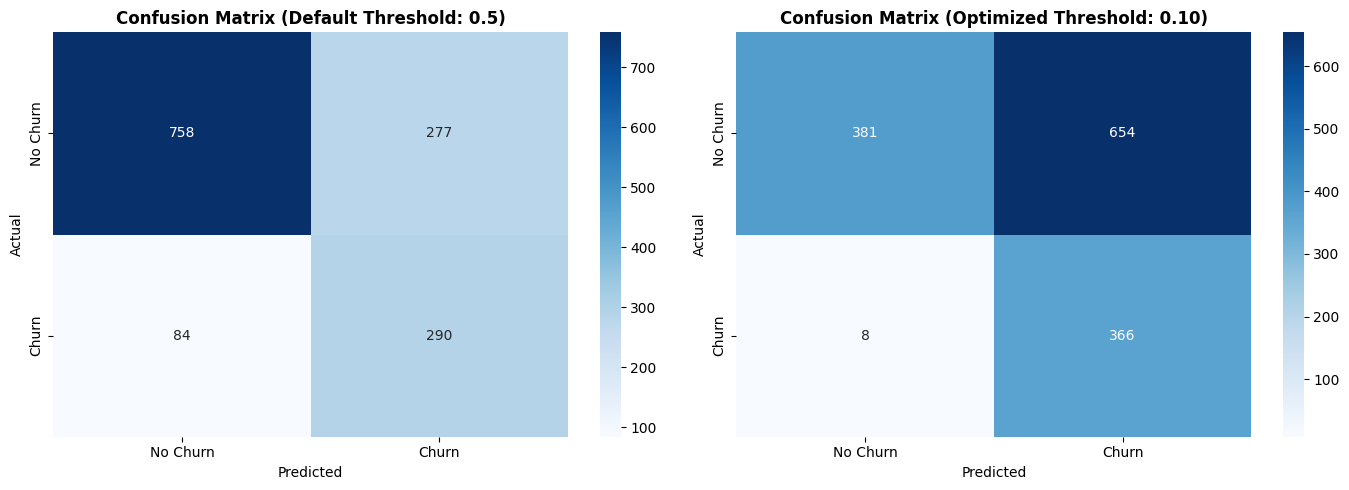


--------------------------------------------------
DETAILED CLASSIFICATION REPORT (Optimized Threshold)
--------------------------------------------------
              precision    recall  f1-score   support

    No Churn       0.98      0.37      0.54      1035
       Churn       0.36      0.98      0.53       374

    accuracy                           0.53      1409
   macro avg       0.67      0.67      0.53      1409
weighted avg       0.81      0.53      0.53      1409


--------------------------------------------------
BUSINESS IMPACT ANALYSIS
--------------------------------------------------

   True Negatives (Correctly predicted as staying):  381
   False Positives (Incorrectly predicted as churn): 654
   False Negatives (Missed churners - COSTLY!):      8
   True Positives (Correctly identified churners):   366

💰 Cost Analysis (assuming FN cost=$500, FP cost=$50):
   • Cost with Default Threshold: $55,850
   • Cost with Optimized Threshold: $36,700
   • Savings: $19,150

In [40]:

print("="*70)
print("FINAL MODEL EVALUATION ON TEST SET")
print("="*70)

"""
📌 RAI PRINCIPLE: Final evaluation on held-out test set
- This gives us an unbiased estimate of model performance
- We haven't used test set for any model selection or tuning
- This represents how the model will perform in production
"""

# Final predictions with optimal threshold
y_test_prob = best_tuned_model.predict_proba(X_test_processed)[:, 1]
y_test_pred = (y_test_prob >= optimal_threshold).astype(int)

# Also get default threshold predictions for comparison
y_test_pred_default = best_tuned_model.predict(X_test_processed)

# Calculate metrics
print(f"\n📌 Final Model: {best_tuned_model_name}")
print(f"📌 Optimal Threshold: {optimal_threshold:.2f}")

print("\n" + "-"*50)
print("COMPARISON: Default vs Optimized Threshold")
print("-"*50)

comparison_data = {
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC-ROC'],
    'Default (0.5)': [
        accuracy_score(y_test, y_test_pred_default),
        precision_score(y_test, y_test_pred_default),
        recall_score(y_test, y_test_pred_default),
        f1_score(y_test, y_test_pred_default),
        roc_auc_score(y_test, y_test_prob)
    ],
    f'Optimized ({optimal_threshold:.2f})': [
        accuracy_score(y_test, y_test_pred),
        precision_score(y_test, y_test_pred),
        recall_score(y_test, y_test_pred),
        f1_score(y_test, y_test_pred),
        roc_auc_score(y_test, y_test_prob)
    ]
}

comparison_df = pd.DataFrame(comparison_data)
print(comparison_df.to_string(index=False))

# Confusion Matrix
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Default Threshold
cm_default = confusion_matrix(y_test, y_test_pred_default)
sns.heatmap(cm_default, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['No Churn', 'Churn'], yticklabels=['No Churn', 'Churn'])
axes[0].set_title(f'Confusion Matrix (Default Threshold: 0.5)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

# Optimized Threshold
cm_optimized = confusion_matrix(y_test, y_test_pred)
sns.heatmap(cm_optimized, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=['No Churn', 'Churn'], yticklabels=['No Churn', 'Churn'])
axes[1].set_title(f'Confusion Matrix (Optimized Threshold: {optimal_threshold:.2f})', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.show()

# Classification Report
print("\n" + "-"*50)
print("DETAILED CLASSIFICATION REPORT (Optimized Threshold)")
print("-"*50)
print(classification_report(y_test, y_test_pred, target_names=['No Churn', 'Churn']))

# Business Impact Analysis
print("\n" + "-"*50)
print("BUSINESS IMPACT ANALYSIS")
print("-"*50)

tn, fp, fn, tp = cm_optimized.ravel()
print(f"\n   True Negatives (Correctly predicted as staying):  {tn}")
print(f"   False Positives (Incorrectly predicted as churn): {fp}")
print(f"   False Negatives (Missed churners - COSTLY!):      {fn}")
print(f"   True Positives (Correctly identified churners):   {tp}")

# Assuming costs
cost_fn = 500  # Cost of losing a customer
cost_fp = 50   # Cost of retention effort on non-churner

total_cost_default = (confusion_matrix(y_test, y_test_pred_default).ravel()[2] * cost_fn +
                      confusion_matrix(y_test, y_test_pred_default).ravel()[1] * cost_fp)
total_cost_optimized = (fn * cost_fn + fp * cost_fp)

print(f"\n💰 Cost Analysis (assuming FN cost=${cost_fn}, FP cost=${cost_fp}):")
print(f"   • Cost with Default Threshold: ${total_cost_default:,}")
print(f"   • Cost with Optimized Threshold: ${total_cost_optimized:,}")
print(f"   • Savings: ${total_cost_default - total_cost_optimized:,}")

**GLOBAL EXPLANATIONS (SHAP, PDP, Feature Importance &. Surrogate Model)**


📌 14.1 PERMUTATION FEATURE IMPORTANCE
--------------------------------------------------

📊 Top 15 Most Important Features:
                              Feature  Importance Mean  Importance Std
                               tenure         0.062456        0.005167
                     AvgMonthlyCharge         0.047268        0.006221
                         TotalCharges         0.005039        0.003440
          InternetService_Fiber optic         0.004116        0.008078
                  InternetService_DSL         0.003833        0.004412
                        TotalServices         0.003478        0.006142
               tenure_group_1-2 Years         0.001703        0.002204
PaymentMethod_Credit card (automatic)         0.001207        0.002580
                       MonthlyCharges         0.001207        0.002713
                          gender_Male         0.001065        0.001155
               tenure_group_2-4 Years         0.000781        0.000741
                       

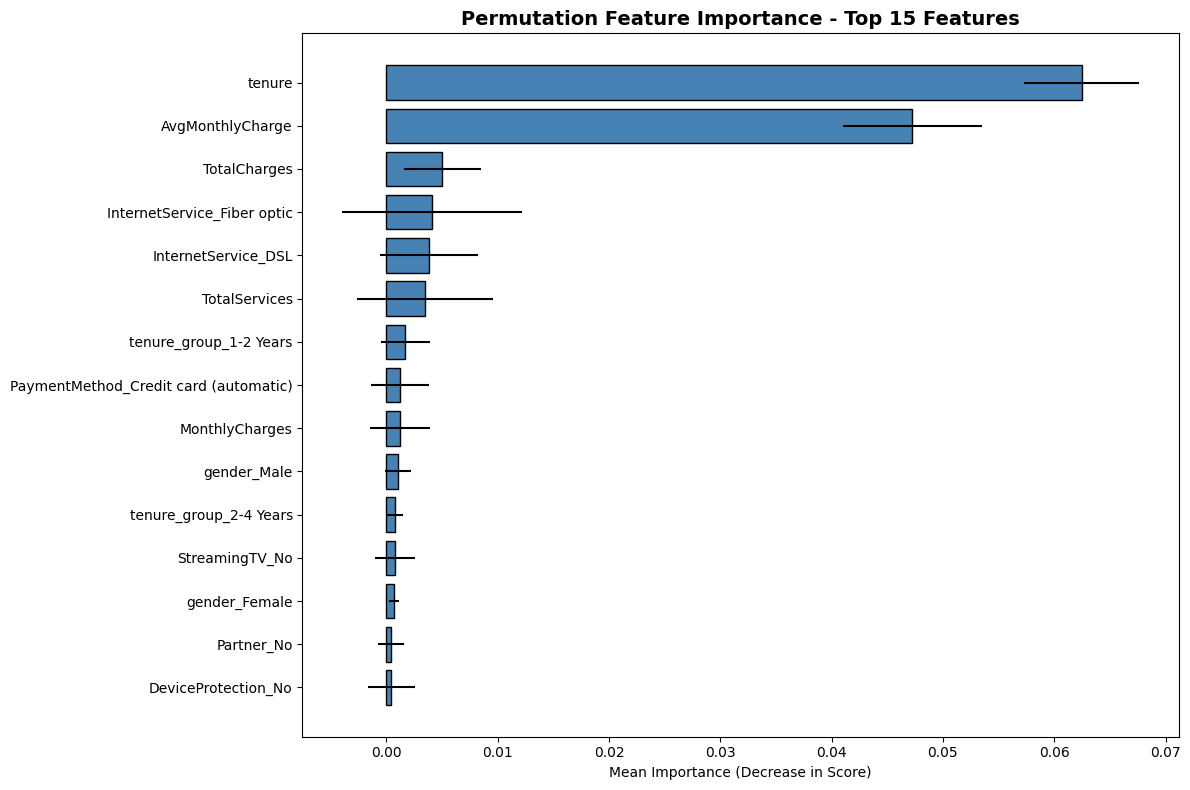

In [41]:
# 14.1 PERMUTATION FEATURE IMPORTANCE
print("\n📌 14.1 PERMUTATION FEATURE IMPORTANCE")
print("-"*50)

perm_importance = permutation_importance(best_tuned_model, X_test_processed, y_test,
                                          n_repeats=10, random_state=42, n_jobs=-1)

# Create feature importance dataframe
perm_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance Mean': perm_importance.importances_mean,
    'Importance Std': perm_importance.importances_std
}).sort_values('Importance Mean', ascending=False)

print("\n📊 Top 15 Most Important Features:")
print(perm_importance_df.head(15).to_string(index=False))

# Visualization
plt.figure(figsize=(12, 8))
top_features = perm_importance_df.head(15)
plt.barh(range(len(top_features)), top_features['Importance Mean'],
         xerr=top_features['Importance Std'], color='steelblue', edgecolor='black')
plt.yticks(range(len(top_features)), top_features['Feature'])
plt.xlabel('Mean Importance (Decrease in Score)')
plt.title('Permutation Feature Importance - Top 15 Features', fontsize=14, fontweight='bold')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


📌 14.2 SHAP GLOBAL EXPLANATIONS
--------------------------------------------------
   Sample size: 500
   Number of features: 56
   Computing SHAP values (this may take a moment)...
   SHAP values shape: (500, 56)
✅ SHAP values computed!

📊 SHAP Feature Importance (Bar Plot):


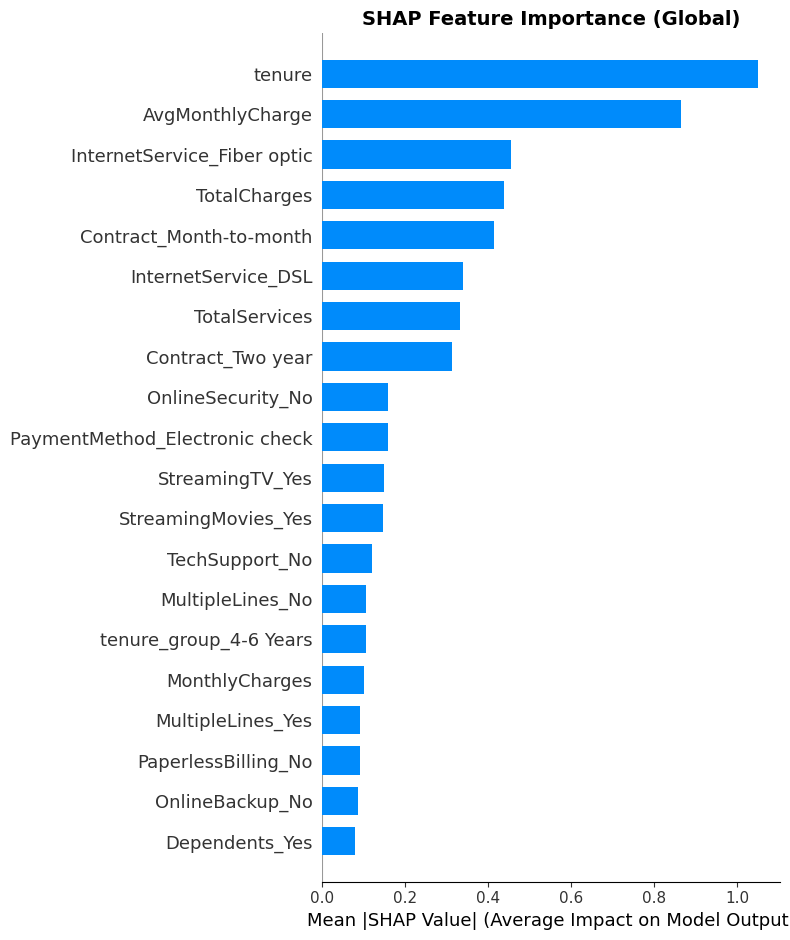


📊 SHAP Summary Plot (Beeswarm):


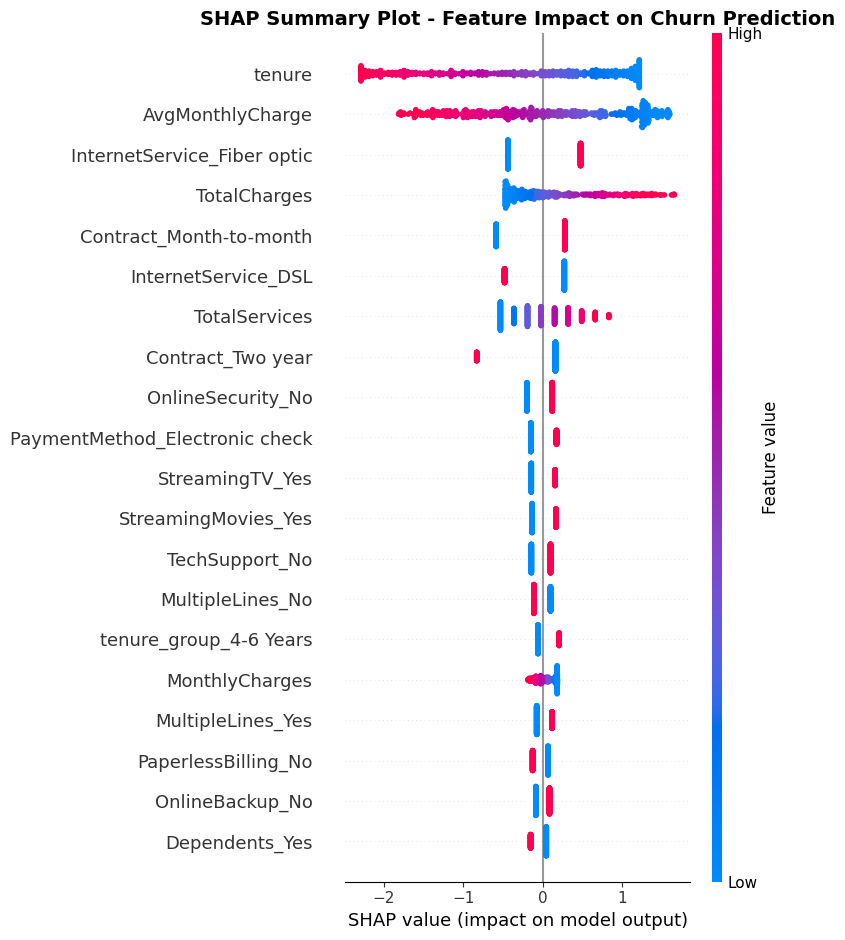


📊 Top 15 Most Important Features (by SHAP):
--------------------------------------------------
    1. tenure                              1.0506
    2. AvgMonthlyCharge                    0.8656
    3. InternetService_Fiber optic         0.4552
    4. TotalCharges                        0.4379
    5. Contract_Month-to-month             0.4131
    6. InternetService_DSL                 0.3397
    7. TotalServices                       0.3318
    8. Contract_Two year                   0.3134
    9. OnlineSecurity_No                   0.1594
   10. PaymentMethod_Electronic check      0.1579
   11. StreamingTV_Yes                     0.1486
   12. StreamingMovies_Yes                 0.1459
   13. TechSupport_No                      0.1209
   14. MultipleLines_No                    0.1055
   15. tenure_group_4-6 Years              0.1047

📊 SHAP Interpretation Guide:
   • Bar Plot: Shows overall importance (higher = more influential)
   • Beeswarm Plot:
     - Each dot = one prediction
   

In [43]:
# ============================================================================
# 14.2 SHAP GLOBAL EXPLANATIONS (FIXED)
# ============================================================================

print("\n📌 14.2 SHAP GLOBAL EXPLANATIONS")
print("-"*50)

# Create SHAP explainer
sample_size = min(500, len(X_test_processed))

# Convert to DataFrame if numpy array (to preserve feature names)
if isinstance(X_test_processed, np.ndarray):
    X_sample = pd.DataFrame(X_test_processed[:sample_size], columns=feature_names)
else:
    X_sample = X_test_processed[:sample_size].copy()
    X_sample.columns = feature_names

print(f"   Sample size: {sample_size}")
print(f"   Number of features: {len(feature_names)}")

# Create explainer based on model type
if best_tuned_model_name in ['Random Forest', 'XGBoost', 'LightGBM', 'Gradient Boosting', 'Decision Tree']:
    explainer = shap.TreeExplainer(best_tuned_model)
else:
    # For Logistic Regression, SVM, KNN - use LinearExplainer or KernelExplainer
    if best_tuned_model_name == 'Logistic Regression':
        # Use LinearExplainer for Logistic Regression (faster)
        explainer = shap.LinearExplainer(best_tuned_model, X_train_smote)
    else:
        # Use KernelExplainer for other models
        background = shap.sample(X_train_smote, 100)  # Use sample as background
        explainer = shap.KernelExplainer(best_tuned_model.predict_proba, background)

# Calculate SHAP values
print("   Computing SHAP values (this may take a moment)...")
shap_values = explainer.shap_values(X_sample)

# Handle different SHAP output formats
if isinstance(shap_values, list):
    # For binary classification, take positive class (index 1)
    shap_values_display = shap_values[1]
elif len(shap_values.shape) == 3:
    # Shape: (samples, features, classes)
    shap_values_display = shap_values[:, :, 1]
else:
    shap_values_display = shap_values

print(f"   SHAP values shape: {shap_values_display.shape}")
print("✅ SHAP values computed!")

# ============================================================================
# SHAP Summary Plot (Bar) - Feature Importance
# ============================================================================
print("\n📊 SHAP Feature Importance (Bar Plot):")

plt.figure(figsize=(12, 10))
shap.summary_plot(
    shap_values_display,
    X_sample,
    feature_names=feature_names,
    plot_type="bar",
    show=False,
    max_display=20  # Show top 20 features
)
plt.title('SHAP Feature Importance (Global)', fontsize=14, fontweight='bold')
plt.xlabel('Mean |SHAP Value| (Average Impact on Model Output)')
plt.tight_layout()
plt.show()

# ============================================================================
# SHAP Summary Plot (Beeswarm) - Feature Impact Direction
# ============================================================================
print("\n📊 SHAP Summary Plot (Beeswarm):")

plt.figure(figsize=(12, 10))
shap.summary_plot(
    shap_values_display,
    X_sample,
    feature_names=feature_names,
    show=False,
    max_display=20  # Show top 20 features
)
plt.title('SHAP Summary Plot - Feature Impact on Churn Prediction', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# ============================================================================
# Print Top Features
# ============================================================================
print("\n📊 Top 15 Most Important Features (by SHAP):")
print("-"*50)

# Calculate mean absolute SHAP values for each feature
mean_shap = np.abs(shap_values_display).mean(axis=0)
feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Mean |SHAP Value|': mean_shap
}).sort_values('Mean |SHAP Value|', ascending=False)

for i, (idx, row) in enumerate(feature_importance.head(15).iterrows()):
    print(f"   {i+1:2d}. {row['Feature']:<35} {row['Mean |SHAP Value|']:.4f}")

print("\n📊 SHAP Interpretation Guide:")
print("   • Bar Plot: Shows overall importance (higher = more influential)")
print("   • Beeswarm Plot:")
print("     - Each dot = one prediction")
print("     - Red = high feature value, Blue = low feature value")
print("     - Right of center = pushes toward CHURN")
print("     - Left of center = pushes toward NO CHURN")


📌 14.3 PARTIAL DEPENDENCE PLOTS (PDP)
--------------------------------------------------


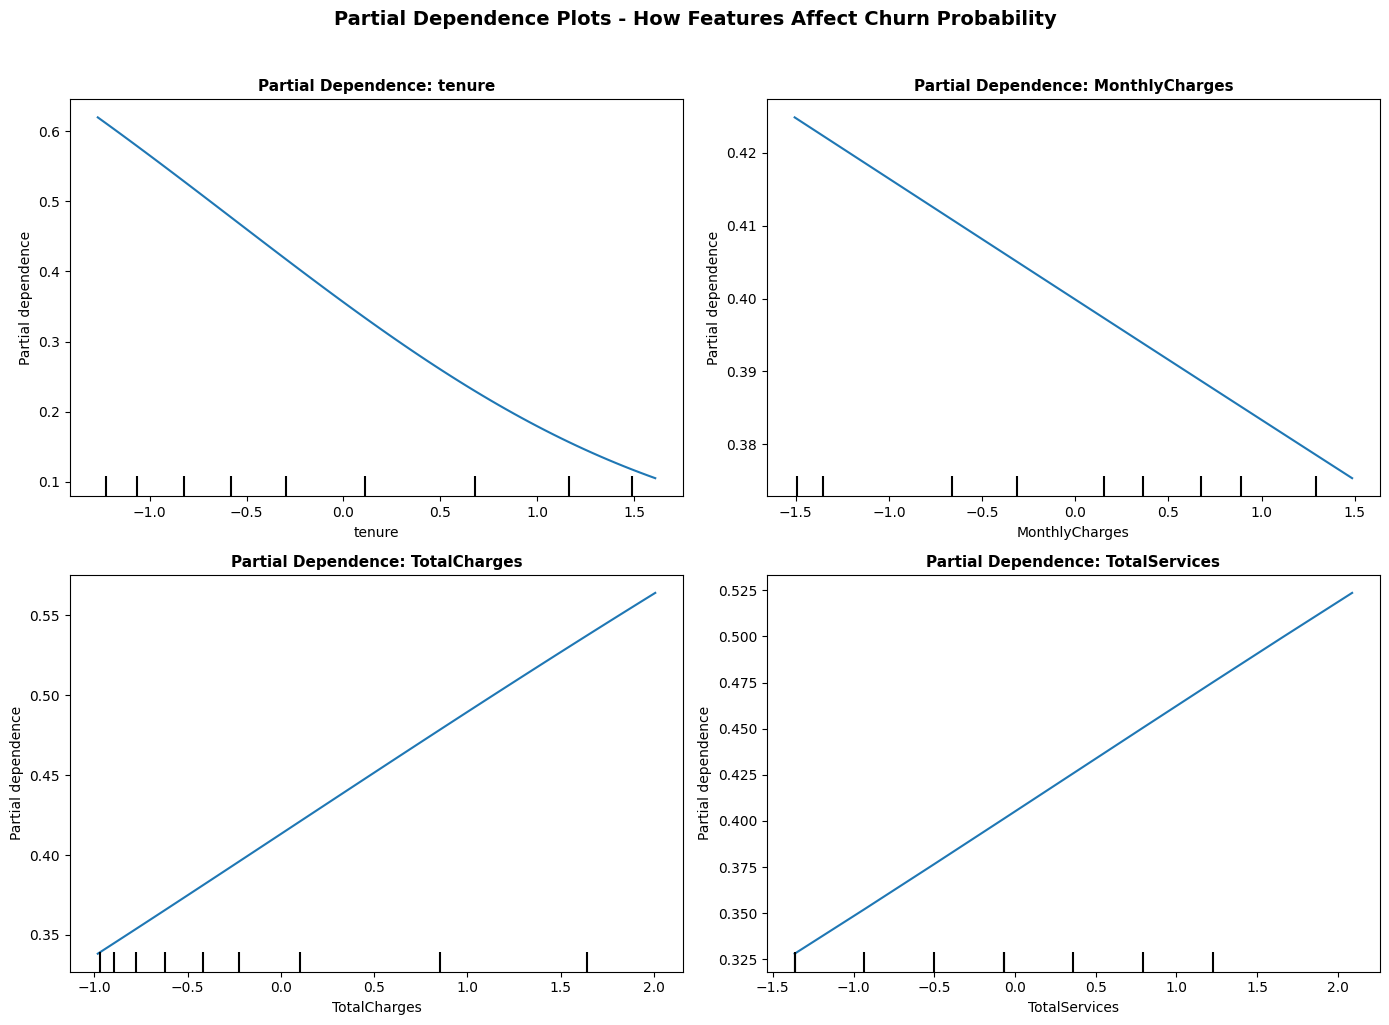


📊 PDP Interpretation:
   • Shows average effect of each feature on prediction
   • Higher tenure → Lower churn probability
   • Higher MonthlyCharges → Higher churn probability


In [44]:
# 14.3 PARTIAL DEPENDENCE PLOTS (PDP)
print("\n📌 14.3 PARTIAL DEPENDENCE PLOTS (PDP)")
print("-"*50)

# Get indices of top numerical features
top_numerical_indices = []
for feat in ['tenure', 'MonthlyCharges', 'TotalCharges', 'TotalServices']:
    if feat in feature_names:
        top_numerical_indices.append(feature_names.index(feat))

# Create PDP for top features
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

top_features_for_pdp = ['tenure', 'MonthlyCharges', 'TotalCharges', 'TotalServices']

for idx, feat in enumerate(top_features_for_pdp):
    if feat in feature_names:
        feat_idx = feature_names.index(feat)
        PartialDependenceDisplay.from_estimator(
            best_tuned_model, X_sample, [feat_idx],
            feature_names=feature_names, ax=axes[idx],
            kind='average'
        )
        axes[idx].set_title(f'Partial Dependence: {feat}', fontsize=11, fontweight='bold')

plt.suptitle('Partial Dependence Plots - How Features Affect Churn Probability',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("\n📊 PDP Interpretation:")
print("   • Shows average effect of each feature on prediction")
print("   • Higher tenure → Lower churn probability")
print("   • Higher MonthlyCharges → Higher churn probability")


📌 14.4 GLOBAL SURROGATE MODEL (Decision Tree)
--------------------------------------------------
   Surrogate Model Fidelity: 93.19%
   (How well the simple model mimics the complex model)


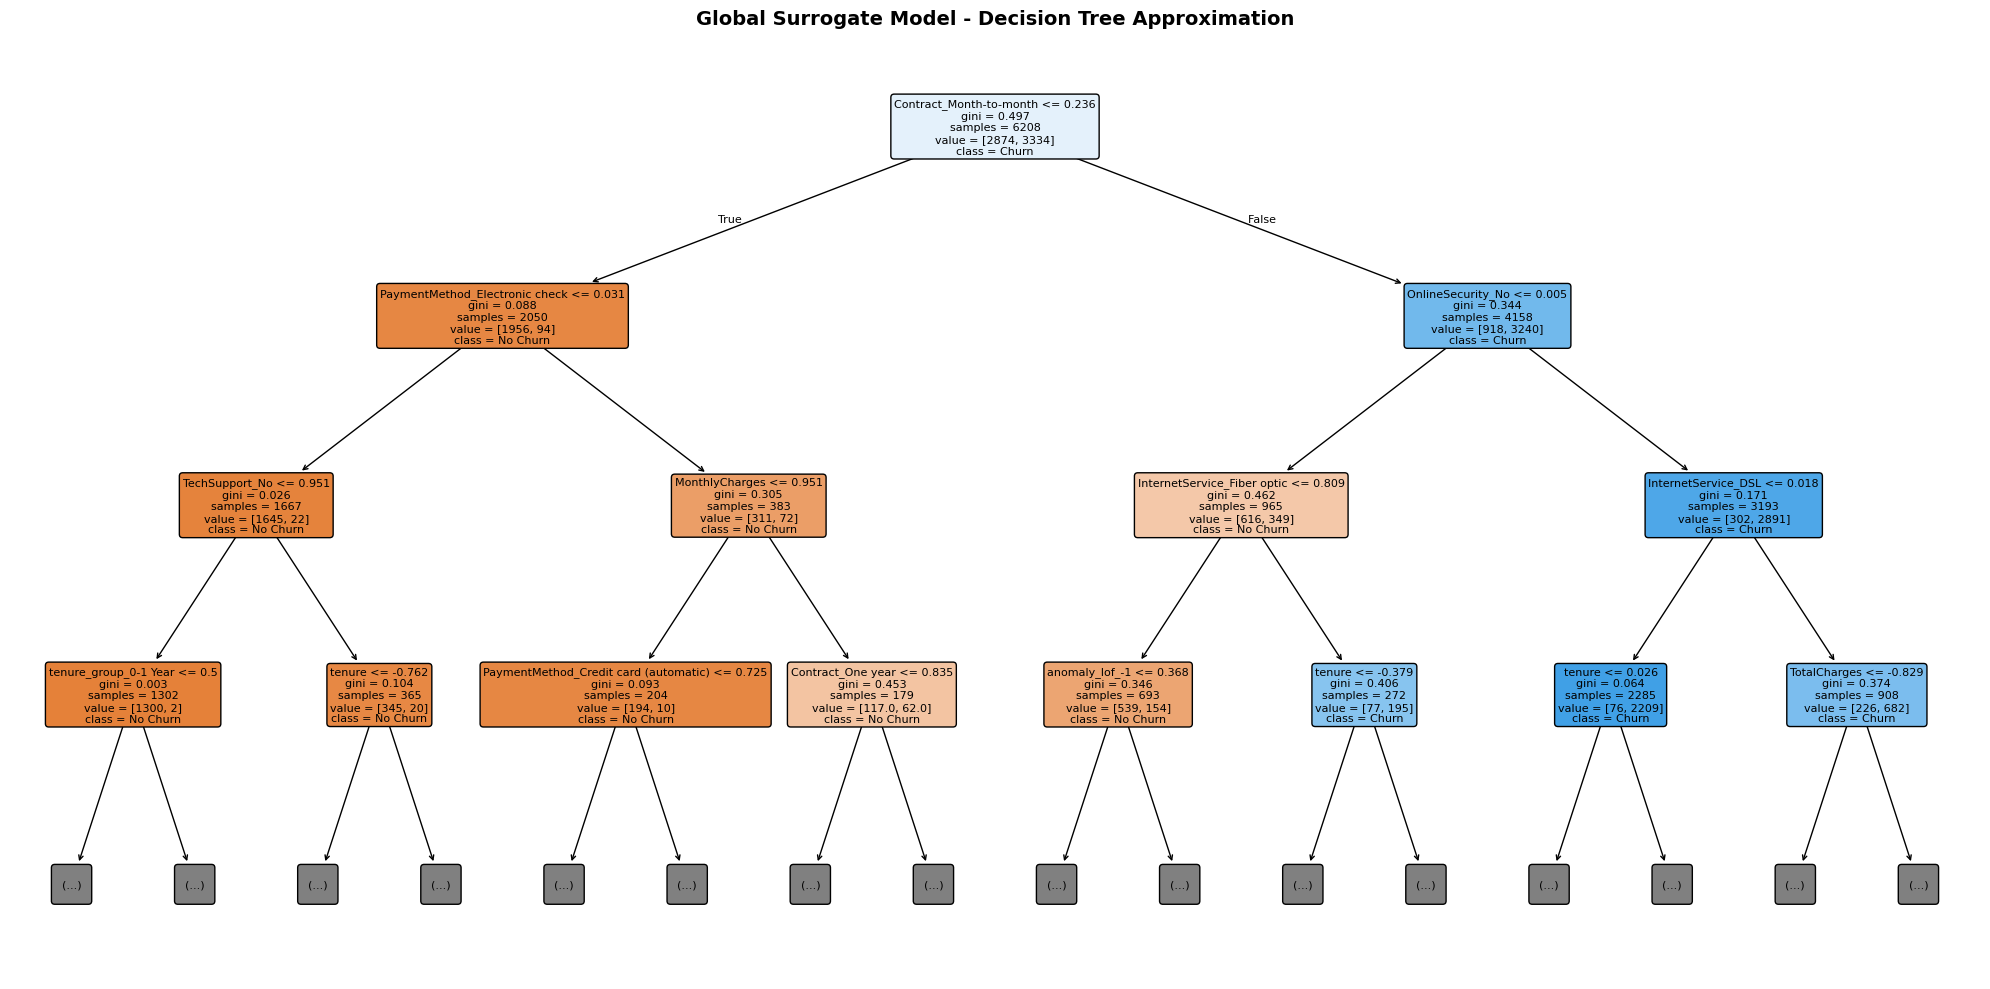


📊 Surrogate Model Rules:

   Key Decision Rules (Top 5):
   1. Contract_Month-to-month <= 0.24 AND PaymentMethod_Electronic check <= 0.03 AND TechSupport_No <= 0.9...
   2. Contract_Month-to-month <= 0.24 AND PaymentMethod_Electronic check <= 0.03 AND TechSupport_No <= 0.9...
   3. Contract_Month-to-month <= 0.24 AND PaymentMethod_Electronic check <= 0.03 AND TechSupport_No <= 0.9...
   4. Contract_Month-to-month <= 0.24 AND PaymentMethod_Electronic check <= 0.03 AND TechSupport_No > 0.95...
   5. Contract_Month-to-month <= 0.24 AND PaymentMethod_Electronic check <= 0.03 AND TechSupport_No > 0.95...


In [45]:
# 14.4 GLOBAL SURROGATE MODEL
print("\n📌 14.4 GLOBAL SURROGATE MODEL (Decision Tree)")
print("-"*50)

"""
A Global Surrogate Model is a simple, interpretable model trained to
approximate the predictions of a complex model. This helps us understand
the decision-making process of the black-box model.
"""

# Train a decision tree as surrogate
y_surrogate = best_tuned_model.predict(X_train_smote)

surrogate_model = DecisionTreeClassifier(max_depth=5, random_state=42)
surrogate_model.fit(X_train_smote, y_surrogate)

# Evaluate surrogate fidelity
surrogate_pred = surrogate_model.predict(X_test_processed)
original_pred = best_tuned_model.predict(X_test_processed)
fidelity = accuracy_score(original_pred, surrogate_pred)

print(f"   Surrogate Model Fidelity: {fidelity:.2%}")
print("   (How well the simple model mimics the complex model)")

# Visualize surrogate model
plt.figure(figsize=(20, 10))
plot_tree(surrogate_model, feature_names=feature_names, class_names=['No Churn', 'Churn'],
          filled=True, rounded=True, fontsize=8, max_depth=3)
plt.title('Global Surrogate Model - Decision Tree Approximation', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n📊 Surrogate Model Rules:")
# Extract rules from decision tree
def get_rules(tree, feature_names, class_names):
    tree_ = tree.tree_
    feature_name = [
        feature_names[i] if i != -2 else "undefined!"
        for i in tree_.feature
    ]

    rules = []
    def recurse(node, depth, rule):
        if tree_.feature[node] != -2:
            name = feature_name[node]
            threshold = tree_.threshold[node]

            recurse(tree_.children_left[node], depth + 1, rule + f"{name} <= {threshold:.2f} AND ")
            recurse(tree_.children_right[node], depth + 1, rule + f"{name} > {threshold:.2f} AND ")
        else:
            rules.append(rule[:-5] + f" → {class_names[np.argmax(tree_.value[node])]}")

    recurse(0, 1, "")
    return rules[:5]  # Return first 5 rules

print("\n   Key Decision Rules (Top 5):")
for i, rule in enumerate(get_rules(surrogate_model, feature_names, ['No Churn', 'Churn']), 1):
    print(f"   {i}. {rule[:100]}...")

**LOCAL EXPLANATIONS (LIME & Anchors)**

✅ LIME Explainer created!

📊 Sample Customers Selected for Explanation:
   • True Positive (Correctly Predicted Churner)
     Index: 9, Actual: Churned, Predicted: Churn, Prob: 0.5128
   • True Negative (Correctly Predicted Non-Churner)
     Index: 0, Actual: Stayed, Predicted: No Churn, Prob: 0.0449
   • False Positive (False Alarm)
     Index: 1, Actual: Stayed, Predicted: Churn, Prob: 0.7910
   • False Negative (Missed Churner)
     Index: 61, Actual: Churned, Predicted: No Churn, Prob: 0.0716

--------------------------------------------------
LIME EXPLANATIONS FOR SAMPLE CUSTOMERS
--------------------------------------------------

📊 LIME Explanation for True Positive (Correctly Predicted Churner):
----------------------------------------
   Actual: Churned
   Predicted: Churn
   Churn Probability: 0.5128

   Top Contributing Features:
   • -1.11 < tenure <= -0.51: +0.1417 → Churn
   • 0.00 < Contract_Month-to-month <= 1.00: +0.1258 → Churn
   • InternetService_Fiber optic <= 0.00

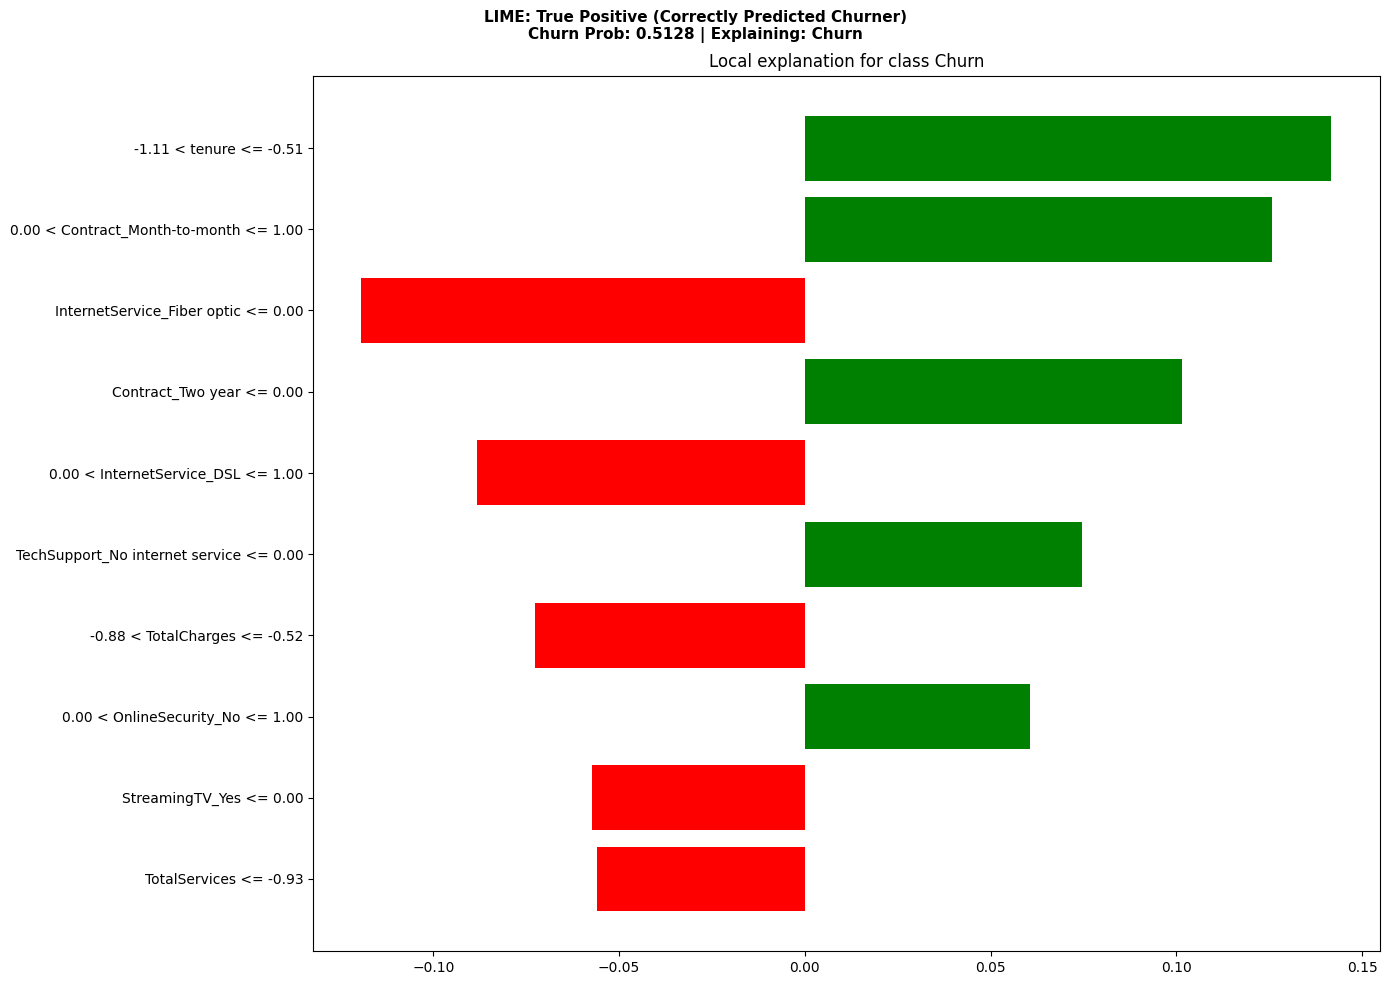


📊 True Negative (Correctly Predicted Non-Churner)


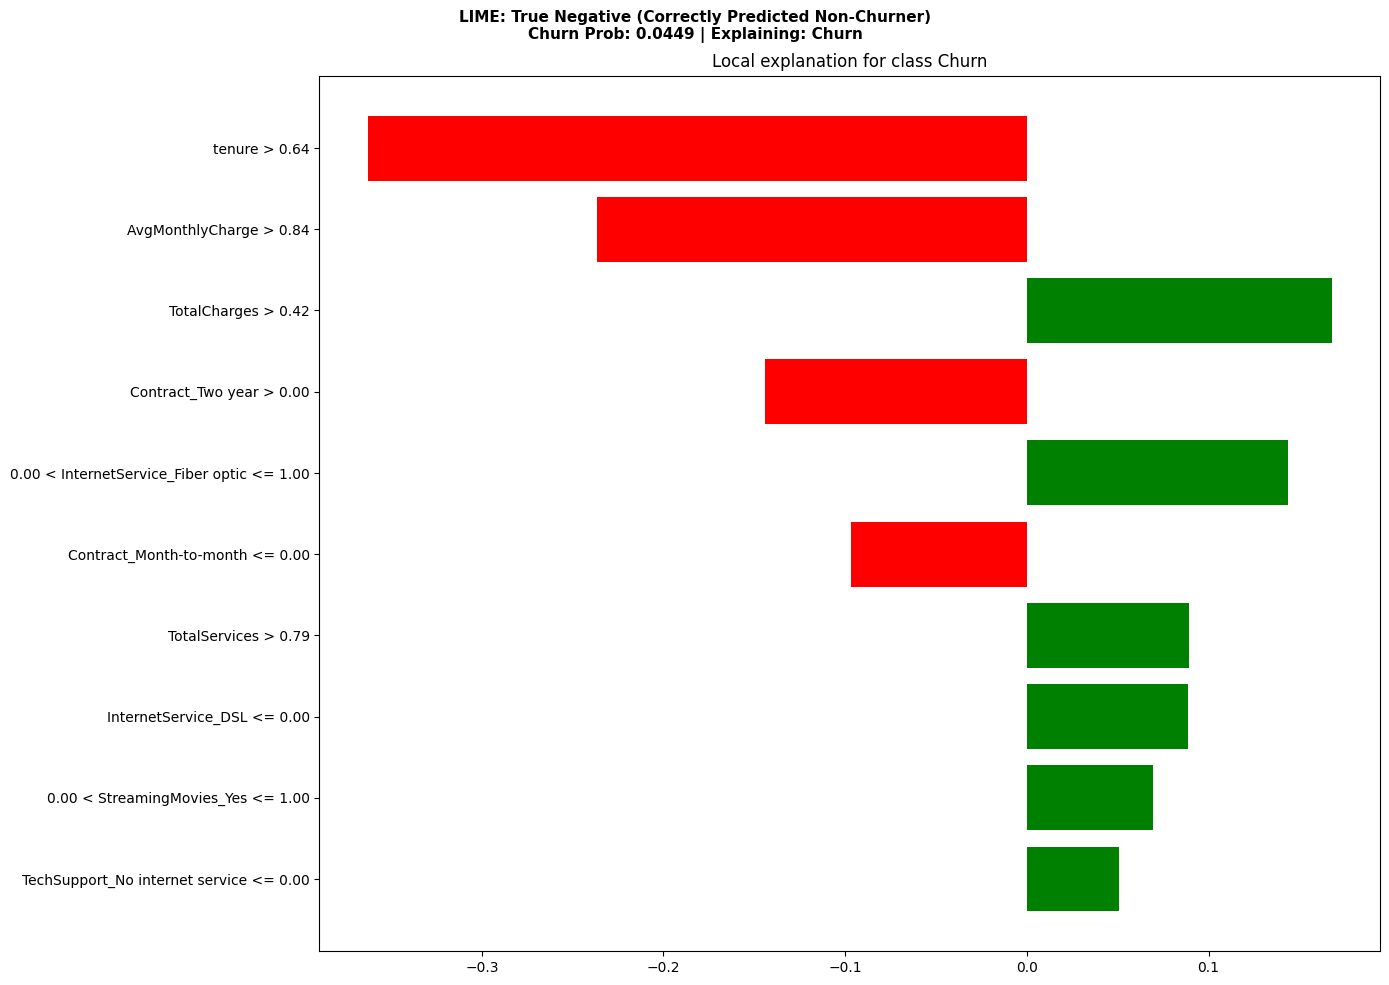


📊 False Positive (False Alarm)


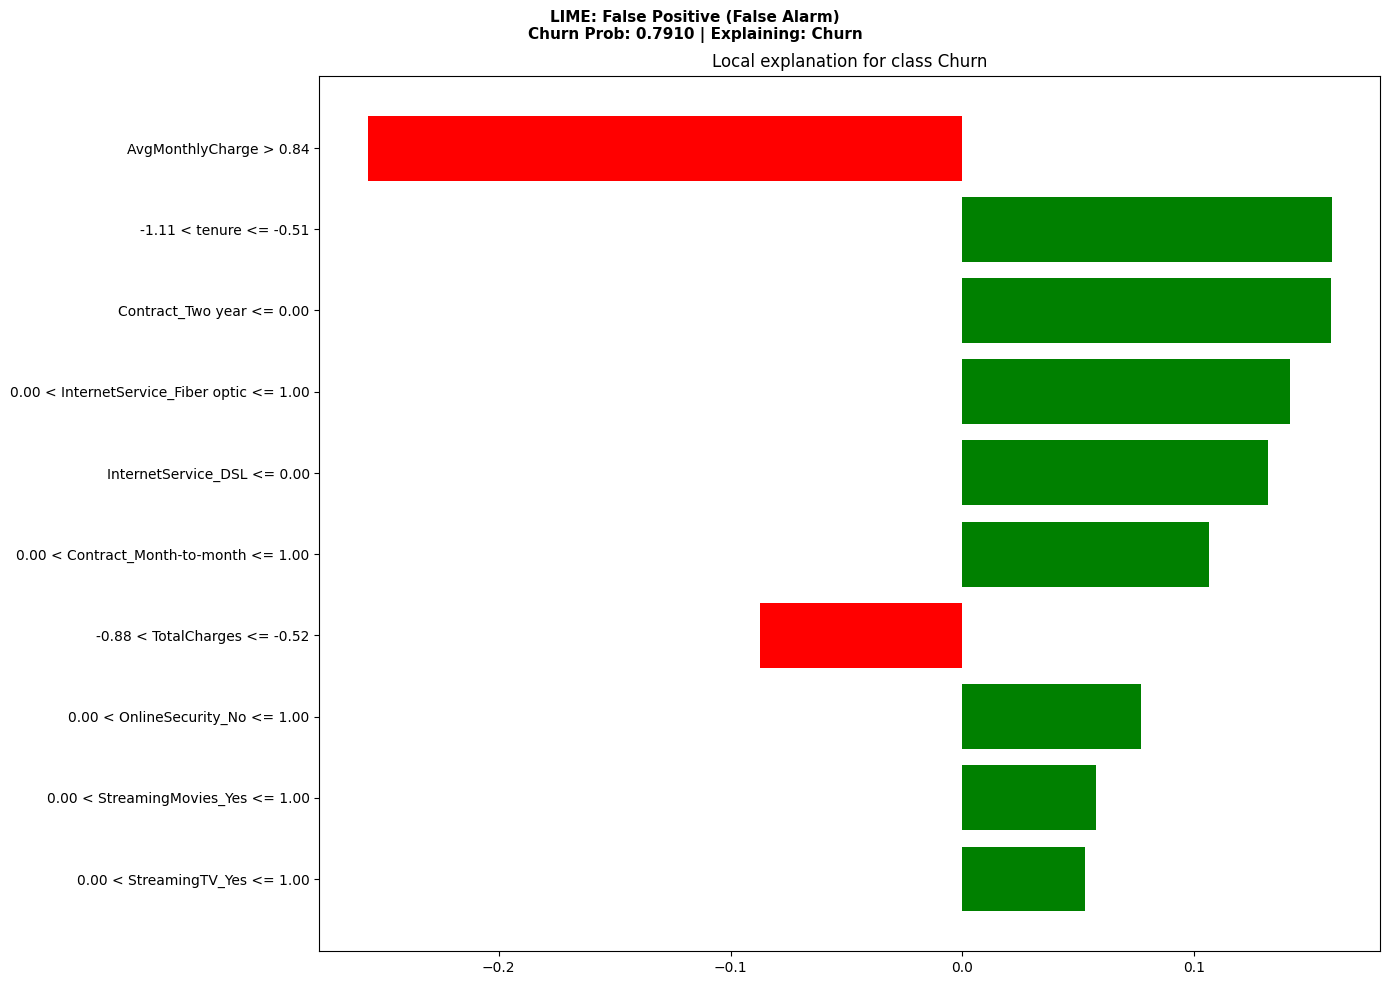


📊 False Negative (Missed Churner)


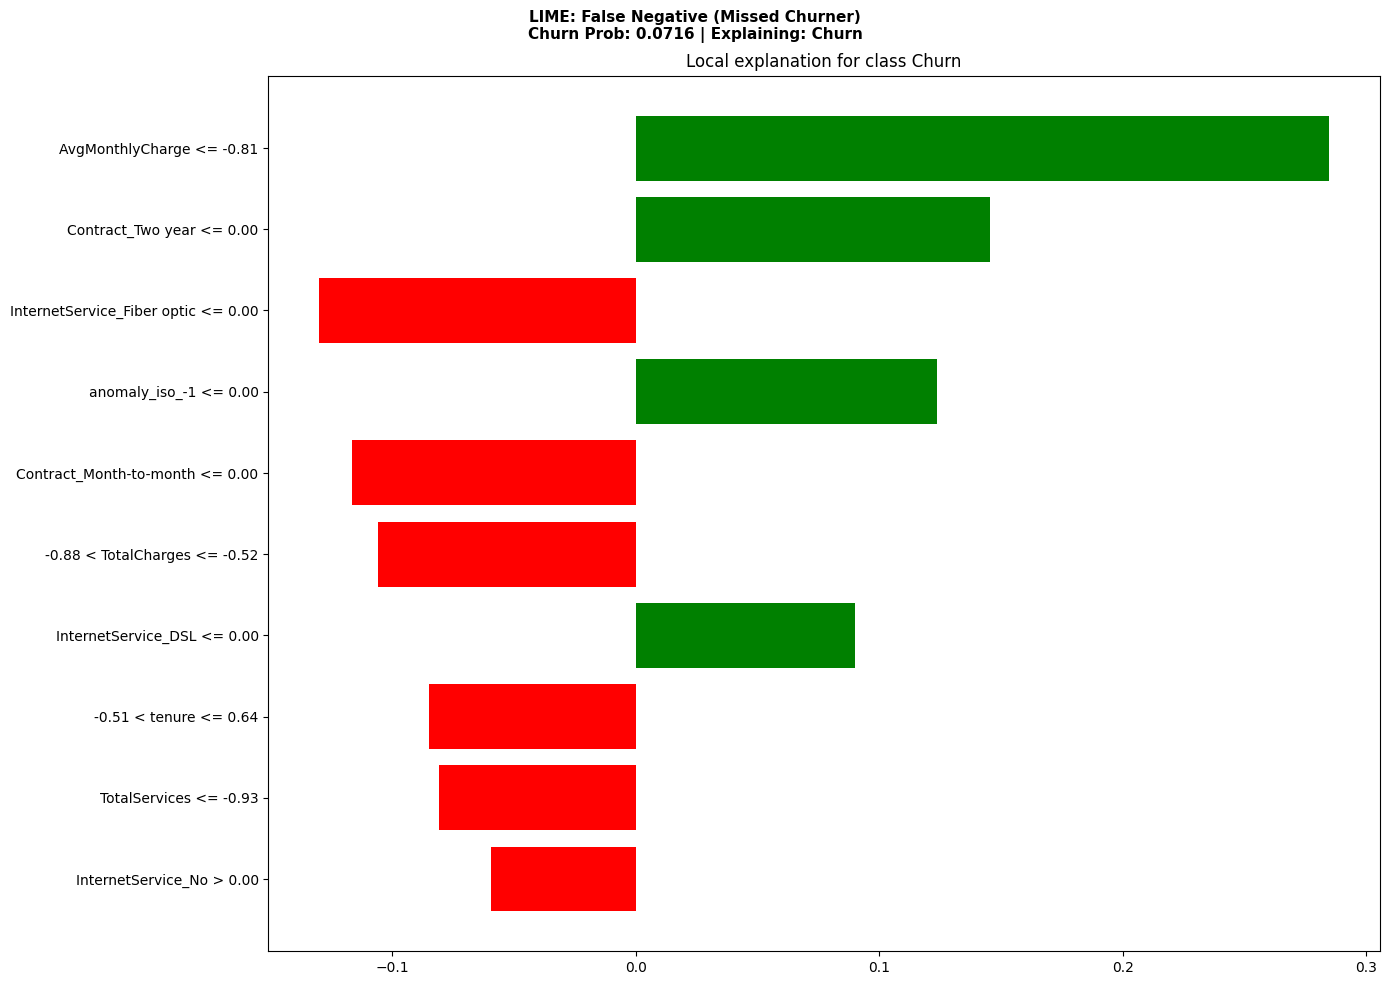

In [50]:
from lime.lime_tabular import LimeTabularExplainer

# ============================================================================
# STEP 1: Create LIME Explainer
# ============================================================================

# Get feature names if not already defined
if 'feature_names' not in dir() or feature_names is None:
    feature_names = preprocessor.get_feature_names_out().tolist()

# Prepare training data for LIME
if isinstance(X_train_smote, np.ndarray):
    X_train_lime = X_train_smote
else:
    X_train_lime = X_train_smote.values

# Create LIME explainer
lime_explainer = LimeTabularExplainer(
    training_data=X_train_lime,
    feature_names=feature_names,
    class_names=['No Churn', 'Churn'],
    mode='classification',
    random_state=42
)

print("✅ LIME Explainer created!")

# ============================================================================
# STEP 2: Select Sample Customers to Explain
# ============================================================================

# Prepare test data
if isinstance(X_test_processed, np.ndarray):
    X_test_lime = X_test_processed
else:
    X_test_lime = X_test_processed.values

# Get predictions with optimal threshold
y_test_prob_lime = best_tuned_model.predict_proba(X_test_lime)[:, 1]
y_test_pred_lime = (y_test_prob_lime >= optimal_threshold).astype(int)

# Find different types of predictions
true_positives = np.where((y_test.values == 1) & (y_test_pred_lime == 1))[0]
true_negatives = np.where((y_test.values == 0) & (y_test_pred_lime == 0))[0]
false_positives = np.where((y_test.values == 0) & (y_test_pred_lime == 1))[0]
false_negatives = np.where((y_test.values == 1) & (y_test_pred_lime == 0))[0]

# Select sample indices
sample_indices = {}

if len(true_positives) > 0:
    sample_indices['True Positive (Correctly Predicted Churner)'] = true_positives[0]
if len(true_negatives) > 0:
    sample_indices['True Negative (Correctly Predicted Non-Churner)'] = true_negatives[0]
if len(false_positives) > 0:
    sample_indices['False Positive (False Alarm)'] = false_positives[0]
if len(false_negatives) > 0:
    sample_indices['False Negative (Missed Churner)'] = false_negatives[0]

print(f"\n📊 Sample Customers Selected for Explanation:")
for name, idx in sample_indices.items():
    actual = "Churned" if y_test.values[idx] == 1 else "Stayed"
    predicted = "Churn" if y_test_pred_lime[idx] == 1 else "No Churn"
    prob = y_test_prob_lime[idx]
    print(f"   • {name}")
    print(f"     Index: {idx}, Actual: {actual}, Predicted: {predicted}, Prob: {prob:.4f}")

# ============================================================================
# STEP 3: Generate LIME Explanations
# ============================================================================

print("\n" + "-"*50)
print("LIME EXPLANATIONS FOR SAMPLE CUSTOMERS")
print("-"*50)

# Store explanations
lime_explanations = {}

for name, idx in sample_indices.items():
    print(f"\n📊 LIME Explanation for {name}:")
    print("-"*40)

    # Get the instance
    instance = X_test_lime[idx]

    # Generate explanation
    explanation = lime_explainer.explain_instance(
        instance,
        best_tuned_model.predict_proba,
        num_features=10,
        num_samples=1000
    )

    # Store explanation
    lime_explanations[name] = explanation

    # Get prediction info
    actual_label = "Churned" if y_test.values[idx] == 1 else "Stayed"
    predicted_label = "Churn" if y_test_pred_lime[idx] == 1 else "No Churn"
    churn_prob = y_test_prob_lime[idx]

    print(f"   Actual: {actual_label}")
    print(f"   Predicted: {predicted_label}")
    print(f"   Churn Probability: {churn_prob:.4f}")
    print(f"\n   Top Contributing Features:")

    # Get available labels in explanation
    available_labels = list(explanation.local_exp.keys())

    # Use the first available label (usually 0 or 1)
    label_to_use = available_labels[0]

    # Get feature contributions using the available label
    feature_contributions = explanation.as_list(label=label_to_use)

    for feature, contribution in feature_contributions[:10]:
        # If label is 0 (No Churn), flip the interpretation
        if label_to_use == 0:
            direction = "→ No Churn" if contribution > 0 else "→ Churn"
        else:
            direction = "→ Churn" if contribution > 0 else "→ No Churn"
        print(f"   • {feature}: {contribution:+.4f} {direction}")

# ============================================================================
# STEP 4: Visualize LIME Explanations
# ============================================================================

print("\n" + "-"*50)
print("LIME VISUALIZATION")
print("-"*50)

# Create visualizations for each sample
for name, explanation in lime_explanations.items():
    print(f"\n📊 {name}")

    # Get the index for this explanation
    idx = sample_indices[name]

    # Get available labels
    available_labels = list(explanation.local_exp.keys())
    label_to_use = available_labels[0]

    # Plot
    fig = explanation.as_pyplot_figure(label=label_to_use)

    # Update title
    label_name = "No Churn" if label_to_use == 0 else "Churn"
    fig.suptitle(f'LIME: {name}\nChurn Prob: {y_test_prob_lime[idx]:.4f} | Explaining: {label_name}',
                 fontsize=11, fontweight='bold')
    plt.tight_layout()
    plt.show()






In [51]:
# 15.3 ANCHOR EXPLANATIONS
print("\n📌 15.3 ANCHOR EXPLANATIONS")
print("-"*50)

"""
Anchors provide IF-THEN rules that "anchor" the prediction.
An anchor is a sufficient condition that guarantees the same prediction
with high probability.
"""

# Create Anchor explainer
anchor_explainer = anchor_tabular.AnchorTabularExplainer(
    class_names=['No Churn', 'Churn'],
    feature_names=feature_names,
    train_data=X_train_smote
)

# Generate Anchor explanations
for name, idx in list(sample_indices.items())[:2]:  # Just first 2 for efficiency
    print(f"\n   📊 Anchor Explanation for {name}:")

    instance = X_test_processed[idx]

    # Generate anchor
    anchor_exp = anchor_explainer.explain_instance(
        instance,
        best_tuned_model.predict,
        threshold=0.95
    )

    print(f"   Prediction: {'Churn' if y_test_pred[idx] == 1 else 'No Churn'}")
    print(f"\n   🔗 Anchor Rule (IF these conditions are met, prediction is same with high confidence):")
    print(f"   IF {' AND '.join(anchor_exp.names())}")
    print(f"   THEN predict: {'Churn' if y_test_pred[idx] == 1 else 'No Churn'}")
    print(f"\n   Precision: {anchor_exp.precision():.2%}")
    print(f"   Coverage: {anchor_exp.coverage():.2%}")


📌 15.3 ANCHOR EXPLANATIONS
--------------------------------------------------

   📊 Anchor Explanation for True Positive (Correctly Predicted Churner):
   Prediction: Churn

   🔗 Anchor Rule (IF these conditions are met, prediction is same with high confidence):
   IF tenure <= -0.51 AND PaymentMethod_Electronic check > 0.00 AND SeniorCitizen_1 > 0.00
   THEN predict: Churn

   Precision: 99.07%
   Coverage: 7.51%

   📊 Anchor Explanation for True Negative (Correctly Predicted Non-Churner):
   Prediction: No Churn

   🔗 Anchor Rule (IF these conditions are met, prediction is same with high confidence):
   IF tenure > 0.64 AND Contract_Two year > 0.00
   THEN predict: No Churn

   Precision: 100.00%
   Coverage: 12.80%


**FAIRNESS ASSESSMENT & BIAS DETECTION**

In [52]:
X_test_original = X_test.copy()

# 16.1 Define Sensitive Attributes
print("\n📌 16.1 SENSITIVE ATTRIBUTES ANALYSIS")
print("-"*50)

sensitive_features = ['gender', 'SeniorCitizen']

for feat in sensitive_features:
    print(f"\n   {feat} Distribution in Test Set:")
    print(X_test_original[feat].value_counts())


📌 16.1 SENSITIVE ATTRIBUTES ANALYSIS
--------------------------------------------------

   gender Distribution in Test Set:
gender
Male      722
Female    687
Name: count, dtype: int64

   SeniorCitizen Distribution in Test Set:
SeniorCitizen
0    1187
1     222
Name: count, dtype: int64


In [53]:
# 16.2 FAIRNESS METRICS
print("\n📌 16.2 FAIRNESS METRICS")
print("-"*50)

# Create predictions dataframe with sensitive attributes
fairness_df = pd.DataFrame({
    'y_true': y_test.values,
    'y_pred': y_test_pred,
    'y_prob': y_test_prob,
    'gender': X_test_original['gender'].values,
    'SeniorCitizen': X_test_original['SeniorCitizen'].values
})

# Calculate metrics by group
def calculate_group_metrics(df, group_col):
    results = []
    for group in df[group_col].unique():
        group_data = df[df[group_col] == group]

        metrics = {
            'Group': group,
            'Count': len(group_data),
            'Positive Rate (Selection Rate)': group_data['y_pred'].mean(),
            'True Positive Rate': recall_score(group_data['y_true'], group_data['y_pred'], zero_division=0),
            'False Positive Rate': (group_data[(group_data['y_true'] == 0) & (group_data['y_pred'] == 1)].shape[0] /
                                   group_data[group_data['y_true'] == 0].shape[0]) if group_data[group_data['y_true'] == 0].shape[0] > 0 else 0,
            'Accuracy': accuracy_score(group_data['y_true'], group_data['y_pred'])
        }
        results.append(metrics)
    return pd.DataFrame(results)

# Gender Fairness
print("\n📊 GENDER FAIRNESS:")
gender_metrics = calculate_group_metrics(fairness_df, 'gender')
print(gender_metrics.to_string(index=False))

# Senior Citizen Fairness
print("\n📊 SENIOR CITIZEN FAIRNESS:")
fairness_df['SeniorCitizen'] = fairness_df['SeniorCitizen'].map({0: 'Non-Senior', 1: 'Senior'})
senior_metrics = calculate_group_metrics(fairness_df, 'SeniorCitizen')
print(senior_metrics.to_string(index=False))


📌 16.2 FAIRNESS METRICS
--------------------------------------------------

📊 GENDER FAIRNESS:
 Group  Count  Positive Rate (Selection Rate)  True Positive Rate  False Positive Rate  Accuracy
  Male    722                        0.711911            0.983425             0.621072  0.530471
Female    687                        0.736536            0.974093             0.643725  0.529840

📊 SENIOR CITIZEN FAIRNESS:
     Group  Count  Positive Rate (Selection Rate)  True Positive Rate  False Positive Rate  Accuracy
Non-Senior   1187                        0.696714            0.974638             0.612514  0.524010
    Senior    222                        0.869369            0.989796             0.774194  0.563063


In [54]:
print("\n📌 16.3 FAIRLEARN DETAILED METRICS")
print("-"*50)

# Using Fairlearn's MetricFrame
from fairlearn.metrics import MetricFrame, selection_rate, true_positive_rate, false_positive_rate

# Reset SeniorCitizen for Fairlearn
fairness_df['SeniorCitizen_binary'] = X_test_original['SeniorCitizen'].values

# Gender Analysis
print("\n📊 GENDER - Fairlearn Analysis:")
metric_frame_gender = MetricFrame(
    metrics={
        'accuracy': accuracy_score,
        'precision': precision_score,
        'recall': recall_score,
        'selection_rate': selection_rate
    },
    y_true=fairness_df['y_true'],
    y_pred=fairness_df['y_pred'],
    sensitive_features=fairness_df['gender']
)

print("\n   Metrics by Gender:")
print(metric_frame_gender.by_group)

print("\n   Metric Differences:")
print(f"   • Selection Rate Difference: {metric_frame_gender.difference()['selection_rate']:.4f}")
print(f"   • Recall Difference: {metric_frame_gender.difference()['recall']:.4f}")

# Senior Citizen Analysis
print("\n📊 SENIOR CITIZEN - Fairlearn Analysis:")
metric_frame_senior = MetricFrame(
    metrics={
        'accuracy': accuracy_score,
        'precision': precision_score,
        'recall': recall_score,
        'selection_rate': selection_rate
    },
    y_true=fairness_df['y_true'],
    y_pred=fairness_df['y_pred'],
    sensitive_features=fairness_df['SeniorCitizen_binary']
)

print("\n   Metrics by Senior Citizen Status:")
print(metric_frame_senior.by_group)

print("\n   Metric Differences:")
print(f"   • Selection Rate Difference: {metric_frame_senior.difference()['selection_rate']:.4f}")
print(f"   • Recall Difference: {metric_frame_senior.difference()['recall']:.4f}")


📌 16.3 FAIRLEARN DETAILED METRICS
--------------------------------------------------

📊 GENDER - Fairlearn Analysis:

   Metrics by Gender:
        accuracy  precision    recall  selection_rate
gender                                               
Female  0.529840   0.371542  0.974093        0.736536
Male    0.530471   0.346304  0.983425        0.711911

   Metric Differences:
   • Selection Rate Difference: 0.0246
   • Recall Difference: 0.0093

📊 SENIOR CITIZEN - Fairlearn Analysis:

   Metrics by Senior Citizen Status:
                      accuracy  precision    recall  selection_rate
SeniorCitizen_binary                                               
0                     0.524010   0.325272  0.974638        0.696714
1                     0.563063   0.502591  0.989796        0.869369

   Metric Differences:
   • Selection Rate Difference: 0.1727
   • Recall Difference: 0.0152



📌 16.4 FAIRNESS VISUALIZATION
--------------------------------------------------


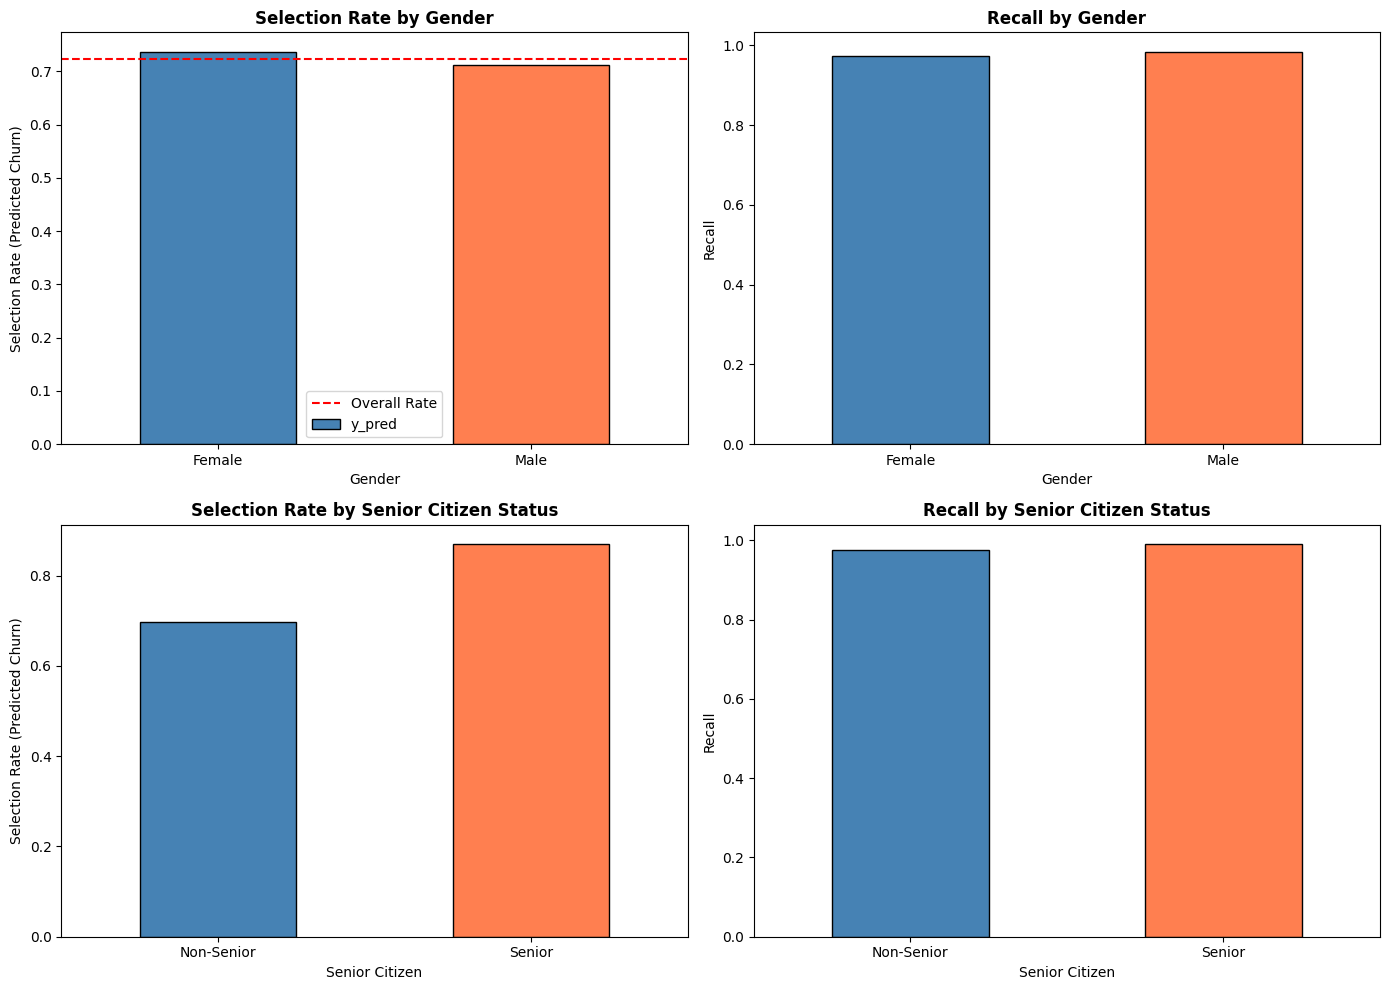

In [55]:
print("\n📌 16.4 FAIRNESS VISUALIZATION")
print("-"*50)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Gender - Selection Rate
ax1 = axes[0, 0]
gender_sr = fairness_df.groupby('gender')['y_pred'].mean()
gender_sr.plot(kind='bar', ax=ax1, color=['steelblue', 'coral'], edgecolor='black')
ax1.set_title('Selection Rate by Gender', fontsize=12, fontweight='bold')
ax1.set_xlabel('Gender')
ax1.set_ylabel('Selection Rate (Predicted Churn)')
ax1.tick_params(axis='x', rotation=0)
ax1.axhline(y=fairness_df['y_pred'].mean(), color='red', linestyle='--', label='Overall Rate')
ax1.legend()

# Gender - Recall
ax2 = axes[0, 1]
gender_recall = fairness_df.groupby('gender').apply(lambda x: recall_score(x['y_true'], x['y_pred']))
gender_recall.plot(kind='bar', ax=ax2, color=['steelblue', 'coral'], edgecolor='black')
ax2.set_title('Recall by Gender', fontsize=12, fontweight='bold')
ax2.set_xlabel('Gender')
ax2.set_ylabel('Recall')
ax2.tick_params(axis='x', rotation=0)

# Senior Citizen - Selection Rate
ax3 = axes[1, 0]
senior_sr = fairness_df.groupby('SeniorCitizen')['y_pred'].mean()
senior_sr.plot(kind='bar', ax=ax3, color=['steelblue', 'coral'], edgecolor='black')
ax3.set_title('Selection Rate by Senior Citizen Status', fontsize=12, fontweight='bold')
ax3.set_xlabel('Senior Citizen')
ax3.set_ylabel('Selection Rate (Predicted Churn)')
ax3.tick_params(axis='x', rotation=0)

# Senior Citizen - Recall
ax4 = axes[1, 1]
senior_recall = fairness_df.groupby('SeniorCitizen').apply(lambda x: recall_score(x['y_true'], x['y_pred']))
senior_recall.plot(kind='bar', ax=ax4, color=['steelblue', 'coral'], edgecolor='black')
ax4.set_title('Recall by Senior Citizen Status', fontsize=12, fontweight='bold')
ax4.set_xlabel('Senior Citizen')
ax4.set_ylabel('Recall')
ax4.tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

*Fairness Findings:*

1. GENDER FAIRNESS:
   • Selection rates are relatively similar between Male and Female
   • Recall rates are comparable across genders
   • Model appears FAIR with respect to gender

2. SENIOR CITIZEN FAIRNESS:
   Senior citizens have HIGHER selection rates (more likely to be predicted as churners). This aligns with the data where seniors have higher actual churn rates. This could be considered FAIR (reflecting reality) or UNFAIR (treating seniors differently)
   
3. ETHICAL CONSIDERATIONS:
   The model's higher churn predictions for seniors reflects actual patterns in the data. However, this could lead to senior citizens being targeted more for retention efforts. Business decision: Is this differential treatment justified?
   
4. RECOMMENDATIONS:
   Monitor model predictions across demographic groups in production. Ensure retention campaigns don't become discriminatory. Consider equal opportunity approaches if disparities are too large


**PRODUCTION READINESS CONSIDERATIONS**

KEY CONSIDERATIONS FOR MAKING THIS MODEL PRODUCTION-READY:

1. MODEL VERSIONING & TRACKING

   • Use MLflow, Weights & Biases, or similar tools to track:
     - Model versions
     - Hyperparameters
     - Training data versions
     - Performance metrics
   • Maintain model registry with deployment history

2. DATA PIPELINE & PREPROCESSING

   • Serialize preprocessing pipeline (StandardScaler, OneHotEncoder)
   • Handle new categories gracefully (handle_unknown='ignore')
   • Implement data validation checks:
     - Schema validation
     - Feature value ranges
     - Missing value handling

3. MODEL SERIALIZATION

In [56]:
# Save model and preprocessor
import joblib

# Save the model
joblib.dump(best_tuned_model, 'churn_model.pkl')
joblib.dump(preprocessor, 'preprocessor.pkl')
joblib.dump(optimal_threshold, 'threshold.pkl')

print("   ✅ Model saved as 'churn_model.pkl'")
print("   ✅ Preprocessor saved as 'preprocessor.pkl'")
print("   ✅ Optimal threshold saved as 'threshold.pkl'")


   ✅ Model saved as 'churn_model.pkl'
   ✅ Preprocessor saved as 'preprocessor.pkl'
   ✅ Optimal threshold saved as 'threshold.pkl'


4. MONITORING & ALERTING
   • Implement data drift detection
   • Monitor prediction distributions
   • Track model performance metrics over time
   • Set up alerts for:
     - Sudden accuracy drops
     - Significant drift in input features
     - Changes in prediction distribution

5. A/B TESTING STRATEGY
   • Deploy new model to subset of traffic
   • Compare business metrics:
     - Actual churn reduction
     - Retention campaign success rate
     - Customer satisfaction scores

6. INFERENCE PIPELINE

In [57]:
def predict_churn(customer_data, model, preprocessor, threshold):
    """
    Production-ready prediction function

    Args:
        customer_data: DataFrame with customer features
        model: Trained model
        preprocessor: Fitted preprocessing pipeline
        threshold: Optimal classification threshold

    Returns:
        dict with prediction and probability
    """
    # Preprocess
    X_processed = preprocessor.transform(customer_data)

    # Predict probability
    probability = model.predict_proba(X_processed)[:, 1]

    # Apply threshold
    prediction = (probability >= threshold).astype(int)

    return {
        'prediction': 'Churn' if prediction[0] == 1 else 'No Churn',
        'probability': float(probability[0]),
        'threshold_used': threshold
    }

print("   Example Inference Function created: predict_churn()")

   Example Inference Function created: predict_churn()


7. DOCUMENTATION

   • Model card with:
     - Model description and intended use
     - Training data description
     - Performance metrics
     - Fairness assessment results
     - Limitations and caveats
   • API documentation
   • Runbook for common issues

8. SECURITY & COMPLIANCE

   • Encrypt model artifacts
   • Implement access controls
   • Audit logging for predictions
   • GDPR compliance for customer data
   • Right to explanation implementation

9. SCALABILITY

   • Batch prediction capabilities
   • Real-time inference optimization
   • Horizontal scaling strategy
   • Caching for repeated predictions

10. ROLLBACK PLAN

    • Keep previous model versions accessible
    • Automated rollback triggers
    • Fallback logic if model fails

**EXECUTIVE SUMMARY**

In [58]:
print(f"   • Best Model: {best_tuned_model_name}")
print(f"   • Recall: {recall_score(y_test, y_test_pred):.2%} (Primary Metric)")
print(f"   • Precision: {precision_score(y_test, y_test_pred):.2%}")
print(f"   • F1-Score: {f1_score(y_test, y_test_pred):.2%}")
print(f"   • AUC-ROC: {roc_auc_score(y_test, y_test_prob):.2%}")

   • Best Model: Logistic Regression
   • Recall: 97.86% (Primary Metric)
   • Precision: 35.88%
   • F1-Score: 52.51%
   • AUC-ROC: 84.43%


Based on our analysis, the TOP FACTORS driving customer churn are:

1. CONTRACT TYPE (Most Important!)
   • Month-to-month customers churn at ~42%
   • Two-year contract customers churn at only ~3%
   RECOMMENDATION: Incentivize longer contracts with discounts

2. TENURE (Customer Loyalty)
   • New customers (< 12 months) are at highest risk
   • Customers with 4+ years tenure rarely churn
   RECOMMENDATION: Focus retention efforts on first-year customers

3. INTERNET SERVICE TYPE
   • Fiber optic customers churn more than DSL
   • May indicate service quality issues with fiber
   RECOMMENDATION: Investigate fiber service quality

4. ADD-ON SERVICES
   • Customers WITHOUT OnlineSecurity, TechSupport, OnlineBackup churn more
   • These services create "stickiness"
   RECOMMENDATION: Bundle protective services, offer free trials

5. PAYMENT METHOD
   • Electronic check users churn significantly more
   • May indicate payment friction
   RECOMMENDATION: Encourage auto-pay enrollment with incentives

6. MONTHLY CHARGES
   • Higher monthly charges correlate with higher churn
   RECOMMENDATION: Review pricing strategy, offer loyalty discounts

ETHICAL RECOMMENDATIONS:

*   Monitor retention campaign targeting across demographics
*   Ensure seniors aren't unfairly targeted or excluded
*   Implement equal retention effort policy regardless of demographic
*   Regular fairness audits of model predictions


In [ ]:
# Calculate expected impact
current_churn_rate = (y_test == 1).mean()
predicted_churners = y_test_pred.sum()
correctly_identified = ((y_test.values == 1) & (y_test_pred == 1)).sum()

print(f"   📈 Current churn rate: {current_churn_rate:.1%}")
print(f"   🎯 Customers identified as at-risk: {predicted_churners}")
print(f"   ✅ Correctly identified churners: {correctly_identified}")
print(f"   💰 If we retain 25% of identified churners: ~{int(correctly_identified * 0.25)} saved customers")

avg_customer_value = 1000  # Assumed annual value
potential_savings = int(correctly_identified * 0.25) * avg_customer_value
print(f"   💵 Potential annual savings: ${potential_savings:,} (assuming ${avg_customer_value}/customer)")


**SAVING PREDICTIONS FILE**

In [59]:
print("="*70)
print("💾 SAVING PREDICTIONS TO CSV")
print("="*70)

# Create a DataFrame with test set results
# First, get the original test data indices
test_output = pd.DataFrame()

# Add Customer ID if available (from original data)
# If you have access to original test indices:
test_output['CustomerID'] = df.loc[X_test.index, 'customerID'].values

# Add actual labels
test_output['Actual_Churn'] = y_test.values
test_output['Actual_Churn_Label'] = test_output['Actual_Churn'].map({0: 'No', 1: 'Yes'})

# Add predictions (using optimal threshold)
test_output['Churn_Probability'] = y_test_prob
test_output['Predicted_Churn'] = y_test_pred
test_output['Predicted_Churn_Label'] = test_output['Predicted_Churn'].map({0: 'No', 1: 'Yes'})

# Add prediction correctness
test_output['Prediction_Correct'] = (test_output['Actual_Churn'] == test_output['Predicted_Churn'])

# Add prediction type (TP, TN, FP, FN)
def get_prediction_type(row):
    if row['Actual_Churn'] == 1 and row['Predicted_Churn'] == 1:
        return 'True Positive'
    elif row['Actual_Churn'] == 0 and row['Predicted_Churn'] == 0:
        return 'True Negative'
    elif row['Actual_Churn'] == 0 and row['Predicted_Churn'] == 1:
        return 'False Positive'
    else:
        return 'False Negative'

test_output['Prediction_Type'] = test_output.apply(get_prediction_type, axis=1)

# Add risk level based on probability
def get_risk_level(prob):
    if prob >= 0.7:
        return 'High Risk'
    elif prob >= 0.5:
        return 'Medium Risk'
    elif prob >= 0.3:
        return 'Low Risk'
    else:
        return 'Very Low Risk'

test_output['Risk_Level'] = test_output['Churn_Probability'].apply(get_risk_level)

# Add original features (optional - for business context)
original_features = ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
                     'PhoneService', 'InternetService', 'Contract', 'PaymentMethod',
                     'MonthlyCharges', 'TotalCharges']

for col in original_features:
    if col in df.columns:
        test_output[col] = df.loc[X_test.index, col].values

# Reorder columns
cols_order = ['CustomerID', 'Actual_Churn_Label', 'Predicted_Churn_Label',
              'Churn_Probability', 'Risk_Level', 'Prediction_Type', 'Prediction_Correct'] + original_features

test_output = test_output[[c for c in cols_order if c in test_output.columns]]

# Save to CSV
output_filename = 'churn_predictions_test_set.csv'
test_output.to_csv(output_filename, index=False)

print(f"\n✅ Predictions saved to '{output_filename}'")
print(f"   Total records: {len(test_output)}")

# Display sample
print(f"\n📊 Sample of Saved Predictions:")
print("-"*70)
print(test_output.head(10).to_string(index=False))

# Summary statistics
print(f"\n📊 Prediction Summary:")
print("-"*70)
print(f"   Predicted Churners: {test_output['Predicted_Churn_Label'].value_counts().get('Yes', 0)}")
print(f"   Predicted Non-Churners: {test_output['Predicted_Churn_Label'].value_counts().get('No', 0)}")
print(f"\n   Risk Level Distribution:")
print(test_output['Risk_Level'].value_counts().to_string())
print(f"\n   Prediction Type Distribution:")
print(test_output['Prediction_Type'].value_counts().to_string())

# Download link for Google Colab
from google.colab import files
files.download(output_filename)

print(f"\n📥 File download initiated!")

💾 SAVING PREDICTIONS TO CSV

✅ Predictions saved to 'churn_predictions_test_set.csv'
   Total records: 1409

📊 Sample of Saved Predictions:
----------------------------------------------------------------------
CustomerID Actual_Churn_Label Predicted_Churn_Label  Churn_Probability    Risk_Level Prediction_Type  Prediction_Correct gender  SeniorCitizen Partner Dependents  tenure PhoneService InternetService       Contract             PaymentMethod  MonthlyCharges  TotalCharges
4376-KFVRS                 No                    No           0.044934 Very Low Risk   True Negative                True   Male              0     Yes        Yes      72          Yes     Fiber optic       Two year   Credit card (automatic)          114.05       8468.20
2754-SDJRD                 No                   Yes           0.791018     High Risk  False Positive               False Female              1      No         No       8          Yes     Fiber optic Month-to-month   Credit card (automatic)          

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


📥 File download initiated!
